# Workbench tool detection with Faster R-CNN / ResNet-18

**EE3703 group project, Group 05.** The detector finds **drills, scissors and screwdrivers** in 640 × 640
workbench photos and reports a box, a class and a confidence for each. It is a two-stage detector: a region
proposal network (RPN) suggests where objects may be, and an RoI head classifies and refines each proposal.

This notebook is the whole Faster R-CNN project in reading order. Data, evaluation and the experiment protocol are
the same as in `YOLO_Project.ipynb`, so the two detectors are compared on equal terms.

| § | Section | What you see |
|---|---|---|
| 1 | Setup | every setting |
| 2 | Data | split sizes, class balance, labelled samples |
| 3 | Preprocessing and augmentation | letterboxing, augmented samples, class-aware sampling |
| 4 | Model | ResNet-18 backbone, anchors, RPN, RoI head |
| 5 | Loss and decoding | anchor labels, the RPN and RoI losses, proposals and detections |
| 6 | Evaluation | COCO AP, P/R/F1, the validation protocol |
| 7 | Training | loop and optimizer; training curves |
| 8 | Validation | chosen RPN NMS and confidence, precision-recall, where objects are lost |
| 9 | Final test | the single evaluation on the 50 original photos, speed and size |
| 10 | Error analysis | which mistakes the detector makes, with examples |
| 11 | Inference | detections on photos |
| 12 | Results and conclusions | metrics against the proposal's targets |

### What was implemented by the group, and what comes from libraries

| Component | Implementation |
|---|---|
| Dataset loading, letterboxing, augmentation, class-aware sampling | Group (NumPy / OpenCV operations) |
| RPN and RoI head, anchor labelling, box encoding/decoding, RPN and RoI losses, proposal filtering, RoI sampling, class-wise detection | Group, with individual PyTorch layers |
| Training loop, optimizer settings | Group |
| Precision/recall/F1, error categories, NMS and confidence selection, timing | Group |
| ResNet-18 backbone with ImageNet weights, anchor generator, RoIAlign, NMS and IoU operators | torchvision |
| AP50 and AP50:95 | pycocotools (official COCO evaluator) |
| Layers, optimizer (SGD), autograd | PyTorch |

**Data protocol.** 358 training and 92 validation images select every setting. The 50 original test photos are used
once, at the end, after retraining on train + validation with the frozen settings.

**Running it.** On Colab: Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all, and upload
`dataset.zip` (from the repository root) when asked. Every setting is in the *Settings* cell of section 1. The final
test is off until `RUN_FINAL_TEST = True`.

> **Box-fix experiment (5 Nov).** Built from the same package as `FasterRCNN_Project.ipynb`. Trains
> `TRIAL = "stride8_v3"` (section 1): `stride8_v2` with the RoI head's box offsets coded as in torchvision and
> background RoIs drawn mostly from partial boxes. Aimed at `stride8_v2`'s errors: 125 of its 213 false positives
> at confidence 0.4 were localization errors (right class, IoU 0.1-0.5 with the object). Results are recorded in
> `development_record.md`.

## 1. Setup

In [43]:
# Install only what is missing (Colab already has PyTorch, torchvision, NumPy, Pillow, OpenCV and Matplotlib).
import importlib.util, subprocess, sys
missing = [package for module, package in [("pycocotools", "pycocotools"), ("cv2", "opencv-python-headless")]
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", *missing], check=True)

In [44]:
# Imports used throughout the notebook
import base64
import copy
import csv
import cv2
import hashlib
import json
import math
import numpy as np
import os
import random
import shutil
import statistics
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from PIL import Image, ImageDraw
from PIL import Image, ImageEnhance, ImageOps
from collections import Counter
from contextlib import redirect_stdout
from dataclasses import asdict, dataclass
from dataclasses import asdict, dataclass, fields
from dataclasses import asdict, dataclass, fields, replace
from dataclasses import asdict, replace
from datetime import datetime, timezone
from html import escape
from io import StringIO
from pathlib import Path
from torch.utils.data import DataLoader
from torch.utils.data import Dataset
from torch.utils.data import Subset
from torch.utils.data import WeightedRandomSampler
from torchvision.models import ResNet18_Weights, resnet18
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.image_list import ImageList
from typing import Any, Callable, Sequence
from typing import Any, Mapping, Sequence
from typing import Mapping, Sequence
import subprocess
import sys
import matplotlib
import matplotlib.pyplot as plt
from datetime import datetime

Project constants and the training configuration. `FasterRCNNConfig` holds every setting that affects training; it is
saved with the run and inside each checkpoint, so the final retrain uses exactly what validation selected.

In [45]:
# workbench_detection/config.py
CLASSES = ("drill", "scissor", "screwdriver")  # class IDs 0, 1, 2; COCO category IDs are these plus 1
IMAGE_SIZE = 640                                # every image is letterboxed to 640 x 640
LETTERBOX_FILL = (114, 114, 114)
IMAGENET_MEAN = (0.485, 0.456, 0.406)           # the ResNet-18 backbone expects ImageNet statistics
IMAGENET_STD = (0.229, 0.224, 0.225)
SEED = 288275
MODEL_NAME = "YOLOv2"
AP_SCORE_FLOOR = 0.001                          # detections below this score are not exported for AP


def seed_everything(seed=SEED):
    """Seed Python, NumPy and PyTorch so runs repeat."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False

In [46]:
# workbench_detection/models/faster_rcnn.py — Faster R-CNN constants
ANCHOR_PROFILES = {"original": (128, 256, 512), "small": (64, 128, 256, 512),
                   "dense": (32, 64, 128, 256, 512),
                   # half-octave steps (x1.41) from 16 px: the size between two dense sizes fits far better
                   "half_octave": (16, 23, 32, 45, 64, 91, 128, 181, 256, 362, 512)}
# Backbone features the RPN and RoI head use: "c4" = ResNet layer 3 (stride 16, 256 channels); "c5" = layer 4
# (stride 32, 512 channels; Person 2's original model); "c3c4" = layer 3 upsampled and added to layer 2 (stride 8).
FEATURE_STRIDES = {"c3c4": 8, "c4": 16, "c5": 32}
# RoI head box offsets. "plain" (Person 2): raw offsets, smooth L1 with beta 1, weight lambda = 10. "standard"
# (torchvision's Faster R-CNN): offsets scaled by (10, 10, 5, 5) and smooth L1 with beta 1/9, weight 1, so errors of
# a few percent of the box size still give a full-size gradient. The RPN keeps the plain coding in both.
BOX_CODERS = {"plain": {"weights": None, "beta": 1.0, "lambda": 10.0},
              "standard": {"weights": (10.0, 10.0, 5.0, 5.0), "beta": 1 / 9, "lambda": 1.0}}
ASPECT_RATIOS = (0.5, 1.0, 2.0)      # anchor height / width
RPN_POSITIVE_IOU = 0.70             # an anchor overlapping an object above this IoU is foreground
RPN_NMS_IOU = 0.70
FINAL_NMS_IOU = 0.50
TRAIN_PROPOSALS = 300
INFERENCE_PROPOSALS = 600

In [47]:
# workbench_detection/engine/faster_rcnn.py
FRCNN_NAME = "Faster R-CNN"
# Anchors kept (highest RPN score) before RPN NMS at inference, chosen on validation with the RPN NMS IoU. The
# fixed default, 10 x 600 proposals, keeps 15% of the 40,000 stride-16 anchors but only 1.7% of 352,000 at stride 8.
PRE_NMS_GRID = (6000, 12000, 24000, 48000)
FRCNN_EMA_DECAY = 0.997  # about 2 epochs of 179 updates, the same averaging horizon as YOLOv2's 0.99 at 45 updates


@dataclass(frozen=True)
class FasterRCNNConfig:
    """Every setting that affects Faster R-CNN training. Defaults are Person 2's measured development run."""

    pretrained_backbone: bool = True   # ImageNet weights for the ResNet-18 backbone
    anchor_profile: str = "dense"      # anchor sizes: "dense" 32-512 px; "half_octave" 16-512 in x1.41 steps
    features: str = ""                 # "c4" stride 16, "c3c4" stride 8 (layers 2 + 3), "c5" stride 32;
                                       # "" = Person 2's pairing: c4 with the dense anchors, c5 otherwise
    roi_pool: int = 0                  # RoIAlign output size (roi_pool x roi_pool); 0 = 5 (c4, c3c4) or 7 (c5)
    roi_fc_layers: int = 1             # fully connected layers of 1024 in the RoI head (torchvision uses 2)
    train_pre_nms: int = 0             # anchors kept before RPN NMS in training; 0 = 10 x train_proposals
    ema: bool = False                  # validate and save an exponential moving average of the weights
    roi_box_coder: str = "plain"       # RoI box offsets: "plain" (Person 2) or "standard" (torchvision; BOX_CODERS)
    roi_hard_negatives: float = 0.0    # share of sampled background RoIs taken from IoU 0.1-0.5 (partial boxes);
                                       # 0 = uniform over all background proposals (Person 2)
    aspect_ratios: tuple = ASPECT_RATIOS  # anchor height / width; 0.25 and 4 add shapes for long, thin tools
    rpn_positive_iou: float = RPN_POSITIVE_IOU  # anchors above this IoU with an object are RPN foreground
    train_proposals: int = TRAIN_PROPOSALS  # proposals kept per image during training (dense profile)
    roi_samples: int = 32              # RoIs sampled per image for the RoI head
    roi_foreground: int = 8            # at most this many of them overlap an object
    augmentation: str = "full"         # the same training augmentation as YOLOv2
    mosaic: float = 0.0
    original_weight: float = 1.0
    batch: int = 2                     # images per update (each image goes through the network on its own)
    lr: float = 5e-4                   # SGD, momentum 0.9, for the backbone
    head_lr_factor: float = 4.0        # RPN and RoI head learn this many times faster (dense profile)
    weight_decay: float = 5e-4
    epochs: int = 10
    patience: int = 10                 # stop after this many epochs without a better validation AP50
    lr_schedule: str = "constant"      # "cosine" decays to 5% of lr (as for YOLOv2)
    warmup_epochs: float = 0.0         # linear warmup from 1% of lr

    def __post_init__(self):
        object.__setattr__(self, "aspect_ratios", tuple(float(ratio) for ratio in self.aspect_ratios))
        checks = {"aspect_ratios": len(self.aspect_ratios) > 0 and all(r > 0 for r in self.aspect_ratios),
                  "rpn_positive_iou": 0.3 <= self.rpn_positive_iou < 1, "train_proposals": self.train_proposals >= 1,
                  "roi_samples": self.roi_samples >= 1, "roi_foreground": 1 <= self.roi_foreground <= self.roi_samples,
                  "lr_schedule": self.lr_schedule in ("constant", "cosine"), "warmup_epochs": self.warmup_epochs >= 0,"anchor_profile": self.anchor_profile in ANCHOR_PROFILES,
                  "features": self.features in ("", *FEATURE_STRIDES), "roi_pool": self.roi_pool >= 0,
                  "roi_fc_layers": self.roi_fc_layers >= 1, "train_pre_nms": self.train_pre_nms >= 0,
                  "roi_box_coder": self.roi_box_coder in BOX_CODERS, "roi_hard_negatives": 0 <= self.roi_hard_negatives <= 1,
                  "augmentation": self.augmentation in ("full", "light"), "mosaic": 0 <= self.mosaic <= 1,
                  "original_weight": self.original_weight > 0, "batch": self.batch >= 1, "lr": self.lr > 0,
                  "head_lr_factor": self.head_lr_factor > 0, "weight_decay": self.weight_decay >= 0,
                  "epochs": self.epochs >= 1, "patience": self.patience >= 1}
        invalid = [name for name, ok in checks.items() if not ok]
        if invalid:
            raise ValueError(f"Invalid training settings: {', '.join(invalid)}")

    def to_dict(self):
        return asdict(self)

    def model_settings(self):
        """Keyword arguments for FasterRCNN_Modular (also saved in each checkpoint)."""
        scales = ANCHOR_PROFILES[self.anchor_profile]
        return {"anchor_scales": scales, "aspect_ratios": self.aspect_ratios,
                "features": self.features or default_features(scales), "pool_size": self.roi_pool or None,
                "roi_fc_layers": self.roi_fc_layers, "roi_box_coder": self.roi_box_coder}

    @classmethod
    def from_dict(cls, values):
        known = {field.name for field in fields(cls)}
        return cls(**{key: value for key, value in dict(values).items() if key in known})

### Settings
The only cell to edit. `TRIAL` picks the recipe:

* **`"baseline"`**: Person 2's development recipe (`FasterRCNNConfig()`), measured at 26.6% validation AP50 on
  Person 2's branch, where the RPN covered only 2 of 47 validation screwdrivers in its top 100 proposals.
* **`"accuracy"`**: the same architecture with changes aimed at that weakness: longer training (up to 60 epochs with
  early stopping after 10 without improvement, as in the proposal) with warmup and cosine decay at a higher learning rate; anchor ratios 0.25 and 4 for long, thin tools; RPN foreground from IoU 0.6
  instead of 0.7 (thin objects rarely reach 0.7 with any anchor); and 128 RoIs per image for the RoI head
  (up to 32 foreground) instead of 32 (up to 8), from 600 training proposals.
* **`"anchors"`**: the accuracy trial with anchor sizes in half-octave steps (16, 23, 32, 45 ... 512 px, 11 sizes
  instead of 5) and RoIAlign 7 × 7 instead of 5 × 5. With the dense sizes, a box between two sizes fits no anchor well:
  only 30 of 47 validation screwdrivers have an anchor at IoU ≥ 0.6 (43 with half-octave sizes). 7 × 7 pooling gives
  the RoI head more detail of thin tools, which it misnamed 10 of 47 times even on the exact box.
* **`"stride8"`**: the `"anchors"` trial on a stride-8 map (80 × 80): layer 3 upsampled and added to layer 2, as one
  level of a feature pyramid, so thin tools cover more feature cells (46 of 47 validation screwdrivers have an
  anchor at IoU ≥ 0.6). About 1.5 times slower per image. Validation AP50 0.769 (run `frcnn_stride8_20261105_0852`).
* **`"stride8_v2"`**: `"stride8"` with changes aimed at screwdrivers (validation AP50 0.505, precision 0.378):
  a second fully connected layer in the RoI head (torchvision's design) to separate screwdrivers from look-alikes;
  24,000 anchors before RPN NMS in training instead of 6,000, so the RoI head trains on proposals for weakly scored
  screwdrivers; and an exponential moving average of the weights (as in YOLOv2) for validation and checkpoints,
  against the epoch-to-epoch swings of up to 0.09 in `"stride8"`'s validation AP50.
* **`"stride8_v2_mosaic"`**: `"stride8_v2"` with 4-image mosaics for half the training samples (YOLOv2's recipe):
  more, smaller objects per image.
* **`"stride8_v3"`**: `"stride8_v2"` with two fixes for its localization errors (125 of 213 false positives: the
  right class but a partial box). The RoI head's box offsets are scaled by (10, 10, 5, 5) and trained with smooth
  L1 at beta 1/9 (torchvision's Faster R-CNN), so errors of a few percent of the box still give a full gradient;
  before, raw offsets with beta 1 gave small errors almost none. And 75% of the background RoIs are partial boxes
  (IoU 0.1-0.5 with an object, Fast R-CNN's background range), so the head learns to score them low.

The recipe with the highest validation AP50 is kept for the final test. Validation also chooses how many
top-scoring anchors enter RPN NMS (6,000 to 48,000; before, always 6,000), with the RPN NMS IoU.

**`SOURCE_RUN`** re-runs validation (with that choice) on a finished run's trained checkpoint without retraining,
in a new run folder; its final test then retrains that run's configuration. Leave it `None` to train `TRIAL`.

Every stage saves its results in the run folder (Google Drive on Colab) and is skipped when re-run if it has already
finished. **After a disconnect**, set `RESUME_RUN` to the run folder's name (printed below) and Run all. **For the
final test**, once the validation results are good, set `RUN_FINAL_TEST = True` (with `RESUME_RUN` if the session has
restarted) and Run all again.

In [48]:
TRIALS = {
    "baseline": FasterRCNNConfig(),  # dense anchors on stride-16 features, SGD lr 5e-4 (heads 4x), batch 2, 10 epochs
    "accuracy": FasterRCNNConfig(epochs=60, lr=1e-3, lr_schedule="cosine", warmup_epochs=1.0,
                                 aspect_ratios=(0.25, 0.5, 1.0, 2.0, 4.0), rpn_positive_iou=0.6,
                                 train_proposals=600, roi_samples=128, roi_foreground=32),
}
TRIALS["anchors"] = FasterRCNNConfig.from_dict({**TRIALS["accuracy"].to_dict(), "anchor_profile": "half_octave",
                                                "roi_pool": 7})
TRIALS["stride8"] = FasterRCNNConfig.from_dict({**TRIALS["anchors"].to_dict(), "features": "c3c4"})
TRIALS["stride8_v2"] = FasterRCNNConfig.from_dict({**TRIALS["stride8"].to_dict(), "roi_fc_layers": 2,
                                                   "train_pre_nms": 24000, "ema": True})
TRIALS["stride8_v2_mosaic"] = FasterRCNNConfig.from_dict({**TRIALS["stride8_v2"].to_dict(), "mosaic": 0.5})
TRIALS["stride8_v3"] = FasterRCNNConfig.from_dict({**TRIALS["stride8_v2"].to_dict(), "roi_box_coder": "standard",
                                                   "roi_hard_negatives": 0.75})
TRIAL = "stride8_v3"        # "stride8_v2", "stride8_v2_mosaic", "stride8_v3"; "accuracy" is the 4 Nov run
SOURCE_RUN = None   # a finished run to re-validate without training, or None to train TRIAL
CONFIG = TRIALS[TRIAL]
RUN_FINAL_TEST = False       # the single evaluation on the 50 original test photos; leave False until settings are final
SAVE_TO_DRIVE = True         # on Colab, keep the run in Google Drive in case the session disconnects
DATASET = Path("/content/dataset") if Path("/content").is_dir() else Path("dataset")
RESUME_RUN = None            # e.g. "frcnn_accuracy_20261104_2130" to continue an earlier run
RUN_NAME = RESUME_RUN or (f"{SOURCE_RUN}_revalidated" if SOURCE_RUN else
                          f"frcnn_{TRIAL}_" + datetime.now().strftime("%Y%m%d_%H%M"))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IN_COLAB = "google.colab" in sys.modules
if not (DATASET / "manifest.csv").is_file() and IN_COLAB:
    from google.colab import files
    archives = [path for path in (Path("/content/dataset.zip"), Path("/content/dataset_fixed.zip")) if path.is_file()]
    if not archives:
        print("Select the dataset zip (dataset.zip from the repository)")
        archives = [Path(name).resolve() for name in files.upload()]  # saved under the uploaded file's own name
    subprocess.run(["unzip", "-q", "-o", str(archives[0]), "-d", "/content"], check=True)
assert (DATASET / "manifest.csv").is_file(), f"Dataset not found at {DATASET}"
if SAVE_TO_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RUNS = Path("/content/drive/MyDrive/EE3703_frcnn_runs")
else:
    RUNS = Path("runs")
seed_everything()
print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))
print(f"Dataset: {DATASET} | run folder: {RUNS / RUN_NAME}")
print(f"Trial: {TRIAL} | configuration:", CONFIG.to_dict())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda (Tesla T4)
Dataset: /content/dataset | run folder: /content/drive/MyDrive/EE3703_frcnn_runs/frcnn_stride8_v3_20261105_1338
Trial: stride8_v3 | configuration: {'pretrained_backbone': True, 'anchor_profile': 'half_octave', 'features': 'c3c4', 'roi_pool': 7, 'roi_fc_layers': 2, 'train_pre_nms': 24000, 'ema': True, 'roi_box_coder': 'standard', 'roi_hard_negatives': 0.75, 'aspect_ratios': (0.25, 0.5, 1.0, 2.0, 4.0), 'rpn_positive_iou': 0.6, 'train_proposals': 600, 'roi_samples': 128, 'roi_foreground': 32, 'augmentation': 'full', 'mosaic': 0.0, 'original_weight': 1.0, 'batch': 2, 'lr': 0.001, 'head_lr_factor': 4.0, 'weight_decay': 0.0005, 'epochs': 60, 'patience': 10, 'lr_schedule': 'cosine', 'warmup_epochs': 1.0}


## 2. Data

500 images in three splits. **Originals** are the group's own workbench photos; **public** images come from open
datasets. Every image is already letterboxed to 640 × 640 and labelled in YOLO and COCO formats; `manifest.csv`
lists each image's split, origin, source and per-class box counts. The test split holds only originals and is
locked: loading it needs `allow_test=True`.

In [49]:
# workbench_detection/data/dataset.py
cv2.setNumThreads(0)  # OpenCV's own threads can hang inside DataLoader worker processes
TRAINING_SPLITS = ("train", "trainval")  # "trainval" = train + valid, only for the final retrain


def read_manifest(root):
    with (Path(root) / "manifest.csv").open(encoding="utf-8-sig", newline="") as handle:
        return list(csv.DictReader(handle))


def normalize(image):
    """RGB uint8 HWC array -> float tensor CHW with ImageNet normalization (what the model takes)."""
    tensor = torch.from_numpy(image.copy()).permute(2, 0, 1).float() / 255
    return (tensor - torch.tensor(IMAGENET_MEAN).view(3, 1, 1)) / torch.tensor(IMAGENET_STD).view(3, 1, 1)


def denormalize(tensor):
    """Undo normalize, for display."""
    image = tensor * torch.tensor(IMAGENET_STD).view(3, 1, 1) + torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    return (image.permute(1, 2, 0).clamp(0, 1) * 255).round().byte().numpy()


class ToolDataset(Dataset):
    """One split of the dataset. Items are (normalized image, target dict with pixel xyxy boxes and labels).

    The test split is locked unless allow_test=True, so it cannot leak into development by accident.
    """

    def __init__(self, root, split, augment=False, mosaic_p=0.0, origin=None, allow_test=False,
                 *, augmentation="full"):
        if split == "test" and not allow_test:
            raise ValueError("The test split is locked; pass allow_test=True only for the final evaluation.")
        if split not in TRAINING_SPLITS and (augment or mosaic_p):
            raise ValueError("Augmentation is for training data only.")
        if augmentation not in ("full", "light"):
            raise ValueError("augmentation must be 'full' or 'light'.")
        self.augmentation = augmentation  # looked up when an image is drawn (see data/augment.py)
        self.root, self.split, self.augment, self.mosaic_p = Path(root), split, augment, mosaic_p
        folders = ("train", "valid") if split == "trainval" else (split,)
        rows = [r for r in read_manifest(self.root)
                if r["split"] in folders and (origin is None or r["origin"] == origin)]
        self.names = [r["file_name"] for r in rows]
        self.origins = [r["origin"] for r in rows]
        self.folders = [r["split"] for r in rows]
        self.boxes, self.labels = [], []
        for name, folder in zip(self.names, self.folders):
            label_path = self.root / folder / "labels" / f"{Path(name).stem}.txt"
            lines = [line.split() for line in label_path.read_text(encoding="utf-8-sig").splitlines() if line]
            values = np.array([[float(v) * IMAGE_SIZE for v in line[1:]] for line in lines], np.float32).reshape(-1, 4)
            # Clip because labels are stored to 6 decimals, which can land a tiny fraction outside the image.
            self.boxes.append(np.stack([values[:, 0] - values[:, 2] / 2, values[:, 1] - values[:, 3] / 2,
                                        values[:, 0] + values[:, 2] / 2, values[:, 1] + values[:, 3] / 2],
                                       axis=1).clip(0, IMAGE_SIZE))
            self.labels.append(np.array([int(line[0]) for line in lines], np.int64))
        self.sample_weights = None  # set by the training sampler; mosaic partners follow the same weights

    def __len__(self):
        return len(self.names)

    def raw(self, index):
        """Image (RGB uint8), pixel xyxy boxes and labels, before augmentation and normalization."""
        image = cv2.cvtColor(cv2.imread(str(self.root / self.folders[index] / "images" / self.names[index])),
                             cv2.COLOR_BGR2RGB)
        return image, self.boxes[index].copy(), self.labels[index].copy()

    def __getitem__(self, index):
        image, boxes, labels = self.raw(index)
        if self.augment:
            # Seeded from torch so each worker and epoch draws a different, reproducible augmentation.
            rng = random.Random(int(torch.randint(0, 2**31 - 1, (1,)).item()))
            transform = AUGMENTATIONS[self.augmentation]
            if rng.random() < self.mosaic_p:
                others = rng.choices(range(len(self)), weights=self.sample_weights, k=3)
                image, boxes, labels = mosaic([transform(*self.raw(i), rng) for i in [index, *others]], rng)
            else:
                image, boxes, labels = transform(image, boxes, labels, rng)
        return normalize(image), {
            "boxes": torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            "labels": torch.as_tensor(labels, dtype=torch.int64),
            "file_name": self.names[index],
            "origin": self.origins[index],
        }


def collate(batch):
    """Images stack into one tensor; targets stay a list because box counts differ between images."""
    return torch.stack([item[0] for item in batch]), [item[1] for item in batch]

Drawing helpers for the figures in this notebook (boxes in green are ground truth, coloured boxes are predictions).

In [50]:
# workbench_detection/visualize.py — figures
CLASS_COLOURS = {"drill": "#1f77b4", "scissor": "#d62728", "screwdriver": "#ff7f0e"}
TRUTH_COLOUR = "#2ca02c"


def _axes_grid(count, columns, size=3.2):
    import matplotlib.pyplot as plt

    rows = max(1, -(-count // columns))
    figure, axes = plt.subplots(rows, columns, figsize=(size * columns, size * rows), squeeze=False)
    for axis in axes.flat:
        axis.axis("off")
    return figure, axes.flat


def draw_boxes(axis, image, boxes=(), labels=(), scores=None, colour=None, title=None):
    """Show an image with xyxy boxes; labels are class IDs, scores optional."""
    from matplotlib.patches import Rectangle

    axis.imshow(image)
    for index, (box, label) in enumerate(zip(boxes, labels)):
        name = CLASSES[int(label)]
        x1, y1, x2, y2 = [float(v) for v in box]
        edge = colour or CLASS_COLOURS[name]
        axis.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=edge, linewidth=2))
        text = name if scores is None else f"{name} {float(scores[index]):.2f}"
        axis.text(x1, max(y1 - 4, 10), text, color="white", fontsize=8, bbox=dict(facecolor=edge, pad=1, linewidth=0))
    if title:
        axis.set_title(title, fontsize=9)
    axis.axis("off")


def draw_detections(image, detections):
    """PIL image with GUI-format detections drawn on it (used by the predict command)."""
    output = image.copy()
    pen = ImageDraw.Draw(output)
    width = max(2, round(max(image.size) / 300))
    for detection in detections:
        colour = CLASS_COLOURS[detection["label"]]
        pen.rectangle(detection["box"], outline=colour, width=width)
        pen.text((detection["box"][0] + width, detection["box"][1] + width),
                 f"{detection['label']} {detection['confidence']:.2f}", fill=colour)
    return output


def split_summary(rows):
    """Images, originals, public and boxes per class for each split, from the manifest rows."""
    table = []
    for split in ("train", "valid", "test"):
        part = [row for row in rows if row["split"] == split]
        table.append({"split": split, "images": len(part),
                      "original": sum(row["origin"] == "original" for row in part),
                      "public": sum(row["origin"] == "public" for row in part),
                      **{name: sum(int(row[name]) for row in part) for name in CLASSES}})
    return table


def plot_class_balance(table):
    import matplotlib.pyplot as plt

    figure, axis = plt.subplots(figsize=(7, 3.2))
    width = 0.25
    for offset, name in enumerate(CLASSES):
        axis.bar(np.arange(len(table)) + (offset - 1) * width, [row[name] for row in table], width,
                 label=name, color=CLASS_COLOURS[name])
    axis.set_xticks(range(len(table)), [row["split"] for row in table])
    axis.set_ylabel("boxes")
    axis.set_title("Boxes per class and split")
    axis.legend()
    plt.show()


def show_samples(dataset, indices, columns=4):
    """Training images with their ground-truth boxes."""
    import matplotlib.pyplot as plt

    _, axes = _axes_grid(len(indices), columns)
    for axis, index in zip(axes, indices):
        image, boxes, labels = dataset.raw(index)
        draw_boxes(axis, image, boxes, labels, title=f"{dataset.names[index]} ({dataset.origins[index]})")
    plt.tight_layout()
    plt.show()


def show_augmentations(dataset, index, count=8, columns=4, seed=0):
    """The same training image drawn several times through the training augmentation."""
    import matplotlib.pyplot as plt
    import torch


    torch.manual_seed(seed)
    _, axes = _axes_grid(count, columns)
    for number, axis in enumerate(axes):
        if number >= count:
            break
        tensor, target = dataset[index]
        draw_boxes(axis, denormalize(tensor), target["boxes"], target["labels"], title=f"draw {number + 1}")
    plt.tight_layout()
    plt.show()


def plot_box_counts(before, after):
    """Boxes per class in one epoch without and with class-aware sampling."""
    import matplotlib.pyplot as plt

    figure, axis = plt.subplots(figsize=(6, 3))
    positions = np.arange(len(CLASSES))
    axis.bar(positions - 0.2, before, 0.4, label="uniform sampling", color="#bbbbbb")
    axis.bar(positions + 0.2, after, 0.4, label="class-aware sampling", color="#1f77b4")
    axis.set_xticks(positions, CLASSES)
    axis.set_ylabel("expected boxes per epoch")
    axis.legend()
    plt.show()

split    images  original  public        drill      scissor  screwdriver
train       358        66     292          174          178          181
valid        92        17      75           52           47           47
test         50        50       0           26           36           28


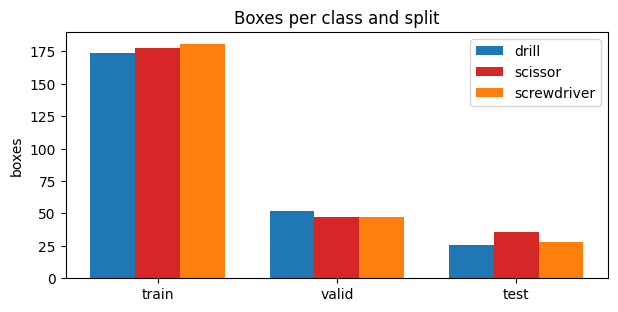

In [51]:
rows = read_manifest(DATASET)
table = split_summary(rows)
print(f"{'split':<7}{'images':>8}{'original':>10}{'public':>8}" + "".join(f"{name:>13}" for name in CLASSES))
for row in table:
    print(f"{row['split']:<7}{row['images']:>8}{row['original']:>10}{row['public']:>8}" + "".join(f"{row[n]:>13}" for n in CLASSES))
plot_class_balance(table)

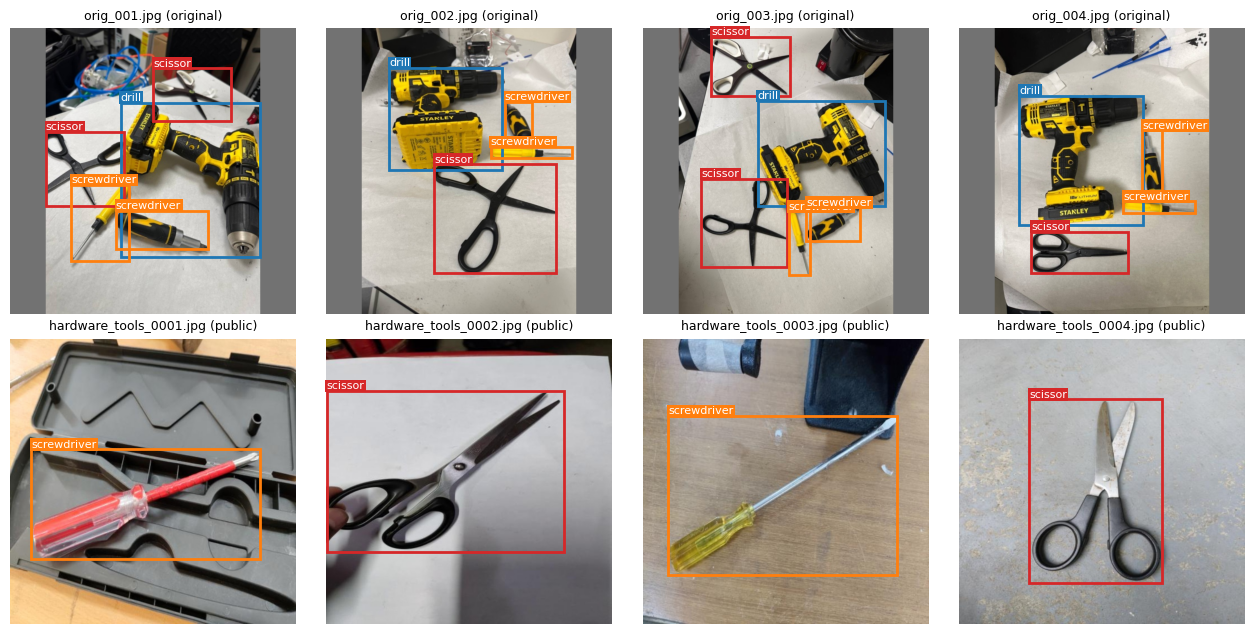

In [52]:
train_set = ToolDataset(DATASET, "train")
originals = [i for i, origin in enumerate(train_set.origins) if origin == "original"]
public = [i for i, origin in enumerate(train_set.origins) if origin == "public"]
show_samples(train_set, originals[:4] + public[:4])

## 3. Preprocessing and augmentation

The same pipeline as the YOLOv2 notebook. **Letterboxing** scales the long side to 640 and pads with grey, so shapes
are never distorted; new photos (section 11) go through the same function.

In [53]:
# workbench_detection/data/transforms.py
def letterbox(image, size=IMAGE_SIZE, fill=LETTERBOX_FILL):
    """Return a padded RGB image and the transform needed to map boxes back to the original pixels."""
    width, height = image.size
    scale = min(size / width, size / height)
    resized_width = max(1, round(width * scale))
    resized_height = max(1, round(height * scale))
    left, top = (size - resized_width) // 2, (size - resized_height) // 2
    canvas = Image.new("RGB", (size, size), fill)
    canvas.paste(image.resize((resized_width, resized_height), Image.Resampling.BILINEAR), (left, top))
    transform = {"scale_x": resized_width / width, "scale_y": resized_height / height,
                 "left": left, "top": top, "width": width, "height": height}
    return canvas, transform


def restore_box(box, transform):
    """Map a 640-canvas xyxy box back to original-image pixels, clipping away the padding."""
    x1, y1, x2, y2 = box

    def restore_x(x):
        return max(0, min(transform["width"], (x - transform["left"]) / transform["scale_x"]))

    def restore_y(y):
        return max(0, min(transform["height"], (y - transform["top"]) / transform["scale_y"]))

    return [restore_x(x1), restore_y(y1), restore_x(x2), restore_y(y2)]

**Training augmentation** (training images only, a different draw every time an image is used): horizontal flip,
rotation within ±15°, shift and scale, brightness/contrast/gamma, hue/saturation, blur or sensor noise, a random grey
cutout, and for scissors a wider scale range and partial occlusion. Every box must stay at least 30% visible.
Faster R-CNN trains without mosaic (`CONFIG.mosaic = 0`).

In [54]:
# workbench_detection/data/augment.py
SCISSOR = 1                    # class ID; scissors get their own scale range and partial occlusion
MIN_VISIBLE = 0.3              # a box must stay at least 30% visible
MIN_SIDE = 4.0                 # and keep both sides at least 4 pixels
GEOMETRIC_TRIES = 5
MOSAIC_TRIES = 10
AUGMENTATION = {
    "horizontal_flip_p": 0.5,
    "rotate_deg": 15.0,
    "translate_fraction": 0.08,
    "scale_range": [0.8, 1.2],
    "brightness_contrast": 0.2,
    "gamma_range": [0.8, 1.25],
    "hue_shift_deg": 8,
    "saturation_range": [0.8, 1.2],
    "blur_p": 0.15,
    "noise_p": 0.15,
    "noise_sigma": 6.0,
    "cutout_p": 0.3,
    "cutout_fraction": 0.2,
    "scissor_scale_range": [0.7, 1.3],
    "scissor_occlusion_p": 0.5,
    "scissor_occlusion_area": [0.1, 0.3],
}


def _visible(boxes, reference_area, bounds=(0, 0, IMAGE_SIZE, IMAGE_SIZE)):
    """Return boxes clipped to bounds and a mask of those that stay usable."""
    clipped = boxes.copy()
    clipped[:, [0, 2]] = clipped[:, [0, 2]].clip(bounds[0], bounds[2])
    clipped[:, [1, 3]] = clipped[:, [1, 3]].clip(bounds[1], bounds[3])
    width, height = clipped[:, 2] - clipped[:, 0], clipped[:, 3] - clipped[:, 1]
    return clipped, (width >= MIN_SIDE) & (height >= MIN_SIDE) & (width * height >= MIN_VISIBLE * reference_area)


def _warp_boxes(boxes, matrix):
    """Apply an affine matrix to the four corners of each box and take their bounding box."""
    corners = np.ones((len(boxes), 4, 3))
    corners[:, 0, :2] = boxes[:, [0, 1]]
    corners[:, 1, :2] = boxes[:, [2, 1]]
    corners[:, 2, :2] = boxes[:, [2, 3]]
    corners[:, 3, :2] = boxes[:, [0, 3]]
    moved = corners @ matrix.T
    return np.concatenate([moved.min(axis=1), moved.max(axis=1)], axis=1)


def geometric(image, boxes, labels, rng):
    """Flip, then try up to 5 random rotation/scale/shift combinations that keep every box usable.

    If none works, only the flip is kept.
    """
    if rng.random() < AUGMENTATION["horizontal_flip_p"]:
        image = image[:, ::-1].copy()
        if len(boxes):
            boxes = boxes.copy()
            boxes[:, [0, 2]] = IMAGE_SIZE - boxes[:, [2, 0]]
    scale_range = AUGMENTATION["scissor_scale_range"] if (labels == SCISSOR).any() else AUGMENTATION["scale_range"]
    shift = AUGMENTATION["translate_fraction"] * IMAGE_SIZE
    for _ in range(GEOMETRIC_TRIES):
        matrix = cv2.getRotationMatrix2D((IMAGE_SIZE / 2, IMAGE_SIZE / 2),
                                         rng.uniform(-AUGMENTATION["rotate_deg"], AUGMENTATION["rotate_deg"]),
                                         rng.uniform(*scale_range))
        matrix[:, 2] += (rng.uniform(-shift, shift), rng.uniform(-shift, shift))
        if not len(boxes):
            return cv2.warpAffine(image, matrix, (IMAGE_SIZE, IMAGE_SIZE), flags=cv2.INTER_LINEAR,
                                  borderValue=LETTERBOX_FILL), boxes, labels
        moved = _warp_boxes(boxes, matrix)
        clipped, usable = _visible(moved, (moved[:, 2] - moved[:, 0]) * (moved[:, 3] - moved[:, 1]))
        if usable.all():
            return cv2.warpAffine(image, matrix, (IMAGE_SIZE, IMAGE_SIZE), flags=cv2.INTER_LINEAR,
                                  borderValue=LETTERBOX_FILL), clipped.astype(np.float32), labels
    return image, boxes, labels


def photometric(image, rng):
    """Brightness, contrast, gamma, hue, saturation, blur and sensor noise. Boxes do not move."""
    limit = AUGMENTATION["brightness_contrast"]
    output = image.astype(np.float32) * rng.uniform(1 - limit, 1 + limit) + 255 * rng.uniform(-limit, limit) / 2
    output = 255 * (output.clip(0, 255) / 255) ** rng.uniform(*AUGMENTATION["gamma_range"])
    hsv = cv2.cvtColor(output.astype(np.uint8), cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[..., 0] = (hsv[..., 0] + rng.uniform(-AUGMENTATION["hue_shift_deg"], AUGMENTATION["hue_shift_deg"]) / 2) % 180
    hsv[..., 1] = (hsv[..., 1] * rng.uniform(*AUGMENTATION["saturation_range"])).clip(0, 255)
    output = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
    if rng.random() < AUGMENTATION["blur_p"]:
        output = cv2.GaussianBlur(output, (5, 5), 0)
    if rng.random() < AUGMENTATION["noise_p"]:
        noise = np.random.default_rng(rng.randrange(2**32)).normal(0, AUGMENTATION["noise_sigma"], output.shape)
        output = (output + noise).clip(0, 255).astype(np.uint8)
    return output


def _try_patch(image, hidden, boxes, x, y, w, h):
    """Grey out a rectangle unless the total hidden area of any box would pass the limit."""
    trial = hidden.copy()
    trial[y:y + h, x:x + w] = True
    for x1, y1, x2, y2 in boxes.astype(int):
        area = trial[y1:y2, x1:x2]
        if area.size and area.mean() > 1 - MIN_VISIBLE:
            return False
    hidden[y:y + h, x:x + w] = True
    image[y:y + h, x:x + w] = LETTERBOX_FILL[0]
    return True


def scissor_occlusion(image, hidden, boxes, labels, rng):
    """Partly cover one scissor box, since thin blades and handles are often occluded."""
    scissors = boxes[labels == SCISSOR]
    if not len(scissors) or rng.random() >= AUGMENTATION["scissor_occlusion_p"]:
        return
    x1, y1, x2, y2 = scissors[rng.randrange(len(scissors))]
    share = rng.uniform(*AUGMENTATION["scissor_occlusion_area"])
    w, h = max(int((x2 - x1) * share ** 0.5), 1), max(int((y2 - y1) * share ** 0.5), 1)
    x = int(rng.uniform(x1, max(x2 - w, x1)))
    y = int(rng.uniform(y1, max(y2 - h, y1)))
    _try_patch(image, hidden, boxes, x, y, min(w, IMAGE_SIZE - x), min(h, IMAGE_SIZE - y))


def cutout(image, hidden, boxes, rng):
    """A grey square at a random place, skipped if it would hide too much of a box."""
    if rng.random() >= AUGMENTATION["cutout_p"]:
        return
    side = int(IMAGE_SIZE * AUGMENTATION["cutout_fraction"] * rng.uniform(0.5, 1))
    _try_patch(image, hidden, boxes, rng.randrange(IMAGE_SIZE - side), rng.randrange(IMAGE_SIZE - side), side, side)


def augment(image, boxes, labels, rng):
    """The full training augmentation for one image."""
    image, boxes, labels = geometric(image, boxes, labels, rng)
    image = photometric(image, rng).copy()
    hidden = np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=bool)
    scissor_occlusion(image, hidden, boxes, labels, rng)
    cutout(image, hidden, boxes, rng)
    return image, boxes, labels


def light_augment(image, boxes, labels, rng):
    """A lighter alternative: horizontal flip, brightness and contrast only."""
    photo = Image.fromarray(image)
    if rng.random() < 0.5:
        photo = ImageOps.mirror(photo)
        boxes = boxes.copy()
        boxes[:, [0, 2]] = image.shape[1] - boxes[:, [2, 0]]
    photo = ImageEnhance.Brightness(photo).enhance(rng.uniform(0.8, 1.2))
    photo = ImageEnhance.Contrast(photo).enhance(rng.uniform(0.8, 1.2))
    return np.asarray(photo), boxes, labels


AUGMENTATIONS = {"full": augment, "light": light_augment}


def mosaic(samples, rng):
    """Join four training images around a random centre; each quadrant keeps only boxes that stay usable."""
    cx, cy = rng.randint(IMAGE_SIZE // 4, 3 * IMAGE_SIZE // 4), rng.randint(IMAGE_SIZE // 4, 3 * IMAGE_SIZE // 4)
    canvas = np.full((IMAGE_SIZE, IMAGE_SIZE, 3), LETTERBOX_FILL[0], dtype=np.uint8)
    regions = [(0, 0, cx, cy), (cx, 0, IMAGE_SIZE, cy), (0, cy, cx, IMAGE_SIZE), (cx, cy, IMAGE_SIZE, IMAGE_SIZE)]
    all_boxes, all_labels = [np.zeros((0, 4), np.float32)], [np.zeros(0, np.int64)]
    for (x1, y1, x2, y2), (image, boxes, labels) in zip(regions, samples):
        width, height = x2 - x1, y2 - y1
        best = None
        # Choose the crop that leaves the fewest cut-off remnants without a label.
        for _ in range(MOSAIC_TRIES):
            offset_x, offset_y = rng.randint(0, IMAGE_SIZE - width), rng.randint(0, IMAGE_SIZE - height)
            moved = boxes.copy()
            moved[:, [0, 2]] += x1 - offset_x
            moved[:, [1, 3]] += y1 - offset_y
            clipped, usable = _visible(moved, (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]), (x1, y1, x2, y2))
            touching = (moved[:, 2] > x1) & (moved[:, 0] < x2) & (moved[:, 3] > y1) & (moved[:, 1] < y2)
            remnants = int((touching & ~usable).sum())
            score = (remnants, -int(usable.sum()))
            if best is None or score < best[0]:
                best = (score, offset_x, offset_y, clipped[usable], labels[usable])
        _, offset_x, offset_y, kept, kept_labels = best
        canvas[y1:y2, x1:x2] = image[offset_y:offset_y + height, offset_x:offset_x + width]
        all_boxes.append(kept.astype(np.float32))
        all_labels.append(kept_labels)
    return canvas, np.concatenate(all_boxes), np.concatenate(all_labels)

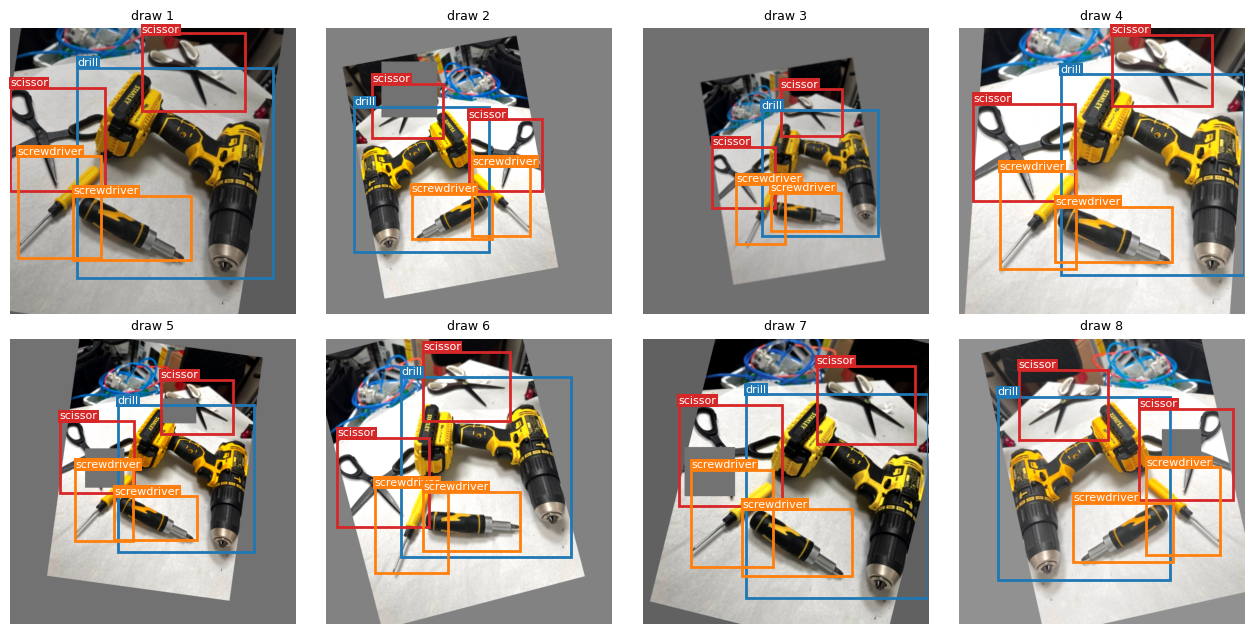

In [55]:
scissor_image = next(i for i, labels in enumerate(train_set.labels) if 1 in labels)
show_augmentations(ToolDataset(DATASET, "train", augment=True, augmentation=CONFIG.augmentation), scissor_image)

**Class-aware sampling.** Each training image is drawn with a weight that boosts the rarest class it contains
(inverse box frequency, capped at 2×), so every class appears about equally often per epoch.

In [56]:
# workbench_detection/data/sampling.py
MAX_CLASS_WEIGHT = 2.0  # minority classes are upweighted by at most 2x


def image_weights(dataset, original_weight=1.0):
    """Per-image sampling weights computed from training boxes only.

    Original photos are weighted first; class weights are then the inverse box frequency under those
    weights, capped at 2x, and each image takes the weight of its rarest class.
    """
    if dataset.split not in TRAINING_SPLITS:
        raise ValueError("Sampling weights are computed from training data only.")
    base = [original_weight if origin == "original" else 1.0 for origin in dataset.origins]
    counts = np.zeros(len(CLASSES))
    for weight, labels in zip(base, dataset.labels):
        counts += weight * np.bincount(labels, minlength=len(CLASSES))
    class_weight = np.minimum(counts.max() / counts, MAX_CLASS_WEIGHT)
    return [weight * (float(class_weight[labels].max()) if len(labels) else 1.0)
            for weight, labels in zip(base, dataset.labels)]


def expected_box_counts(dataset, weights):
    """Boxes per class one epoch is expected to contain under the given weights."""
    scale = len(weights) / sum(weights)
    counts = np.zeros(len(CLASSES))
    for weight, labels in zip(weights, dataset.labels):
        counts += scale * weight * np.bincount(labels, minlength=len(CLASSES))
    return counts


def make_train_sampler(dataset, original_weight=1.0, generator=None):
    weights = image_weights(dataset, original_weight)
    dataset.sample_weights = weights
    return WeightedRandomSampler(weights, num_samples=len(dataset), replacement=True, generator=generator)

Expected boxes per epoch: {'drill': '174 -> 177', 'scissor': '178 -> 177', 'screwdriver': '181 -> 181'}


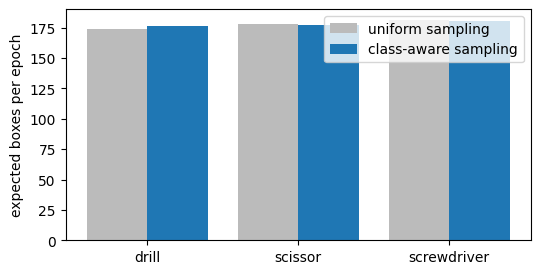

In [57]:
weights = image_weights(train_set, CONFIG.original_weight)
uniform, balanced = expected_box_counts(train_set, [1.0] * len(train_set)), expected_box_counts(train_set, weights)
print("Expected boxes per epoch:", {n: f"{u:.0f} -> {b:.0f}" for n, u, b in zip(CLASSES, uniform, balanced)})
plot_box_counts(uniform, balanced)

## 4. Model

Box utilities used by the evaluator (IoU of two boxes and format conversion).

In [58]:
# workbench_detection/boxes.py
def xywh_to_xyxy(boxes):
    """Centre-format boxes (..., 4) to corner format."""
    return torch.cat((boxes[..., :2] - boxes[..., 2:] / 2, boxes[..., :2] + boxes[..., 2:] / 2), -1)


def pixels_to_cxcywh(boxes):
    """Pixel xyxy boxes on the 640 canvas to normalized centre format, the YOLO target encoding."""
    return torch.stack([(boxes[:, 0] + boxes[:, 2]) / 2, (boxes[:, 1] + boxes[:, 3]) / 2,
                        boxes[:, 2] - boxes[:, 0], boxes[:, 3] - boxes[:, 1]], dim=1) / IMAGE_SIZE


def box_iou(a, b):
    """Pairwise IoU between xyxy tensors a (N, 4) and b (M, 4) -> (N, M)."""
    inter = (torch.minimum(a[:, None, 2:], b[None, :, 2:]) - torch.maximum(a[:, None, :2], b[None, :, :2])).clamp(min=0).prod(-1)
    area_a = (a[:, 2:] - a[:, :2]).clamp(min=0).prod(-1)
    area_b = (b[:, 2:] - b[:, :2]).clamp(min=0).prod(-1)
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def wh_iou(a, b):
    """IoU of width/height pairs aligned at a common centre: (N, 2) x (M, 2) -> (N, M). Used for anchors."""
    inter = torch.minimum(a[:, None], b[None]).prod(-1)
    return inter / (a.prod(-1)[:, None] + b.prod(-1)[None] - inter + 1e-9)


def pair_iou(box_a, box_b):
    """IoU of two pixel xyxy boxes given as plain sequences (exact float arithmetic, for scoring)."""
    intersection = max(0.0, min(box_a[2], box_b[2]) - max(box_a[0], box_b[0])) * max(
        0.0, min(box_a[3], box_b[3]) - max(box_a[1], box_b[1]))
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0

**Architecture.** A ResNet-18 backbone (ImageNet weights) produces a feature map. By default (`features` `c4`) it
stops after layer 3 (stride 16, 256 channels, a 40 × 40 map) so small screwdrivers cover several feature cells.
`c3c4` (the `stride8` trial) upsamples layer 3 and adds it to a 1 × 1 projection of layer 2, then smooths the sum
with a 3 × 3 convolution: a stride-8, 80 × 80 map. `c5`, layer 4 at stride 32, is Person 2's original model.

* **Anchors**: at every feature cell, one box per size × aspect ratio (dense: 5 sizes 32–512 px × ratios 0.5/1/2 = 15;
  the accuracy trial adds ratios 0.25 and 4, giving 25; half-octave sizes give 11 × 5 = 55).
* **RPN**: a 3×3 convolution, then per anchor one objectness score and four box offsets.
* **RoI head**: RoIAlign pools each proposal to `roi_pool` × `roi_pool` features (default 5 × 5 on c4, 7 × 7 on c5); a fully connected layer of 1024
  units feeds a 4-way classifier (background + 3 tools) and class-specific box offsets.

In [59]:
# workbench_detection/models/faster_rcnn.py
class RPN(nn.Module):

    def __init__(self, in_channels=512, num_anchors=9):
        super().__init__()

        # Intermediate 3x3 convolution
        self.rpn_head = nn.Sequential(
            nn.Conv2d(
                in_channels, in_channels,
                kernel_size=3, stride=1, padding=1
            ),
            nn.ReLU()
        )

        # Objectness classification head
        self.cls_logits = nn.Conv2d(
            in_channels, num_anchors,
            kernel_size=1, stride=1
        )

        # Bounding box regression head
        self.bbox_pred = nn.Conv2d(
            in_channels, num_anchors * 4,
            kernel_size=1, stride=1
        )

    def forward(self, x):
        t = self.rpn_head(x)
        return self.cls_logits(t), self.bbox_pred(t)

class Stage2_network(nn.Module):

    def __init__(self, in_channels=512, num_classes=4, *, stride=32, pool_size=7, fc_layers=1):
        super().__init__()

        # Region of Interest (RoI) Align
        self.roi_align = torchvision.ops.RoIAlign(
            output_size=(pool_size, pool_size),
            spatial_scale=1.0 / stride,
            sampling_ratio=2,
            aligned=True
        )

        # Fully connected layers (Person 2: one; torchvision's Faster R-CNN head: two)
        layers, width = [], in_channels * pool_size ** 2
        for _ in range(fc_layers):
            layers += [nn.Linear(in_features=width, out_features=1024),
                       nn.LeakyReLU(0.01) if stride < 32 else nn.ReLU()]
            width = 1024
        self.fc = nn.Sequential(*layers)

        # Classification head
        self.cls_score = nn.Linear(
            1024, num_classes
        )

        # Bounding box regression head
        self.bbox_head = nn.Linear(
            1024, (num_classes - 1) * 4
        )

    def forward(self, features, proposals):

        pooled = self.roi_align(features, proposals)

        x = pooled.flatten(start_dim=1)

        x = self.fc(x)

        return self.cls_score(x), self.bbox_head(x)

def default_features(anchor_scales):
    """Features of checkpoints saved before `features` existed: the dense anchors meant layer 3, others layer 4."""
    return "c4" if tuple(anchor_scales) == ANCHOR_PROFILES["dense"] else "c5"


class FPNMerge(nn.Module):
    """Layer 3 (stride 16) upsampled and added to a 1x1 projection of layer 2 (stride 8), then a 3x3 smoothing
    convolution: the stride-8 map keeps layer 2's position detail and layer 3's semantics (one FPN level)."""

    def __init__(self, fine_channels=128, coarse_channels=256):
        super().__init__()
        self.lateral = nn.Conv2d(fine_channels, coarse_channels, kernel_size=1)
        self.smooth = nn.Conv2d(coarse_channels, coarse_channels, kernel_size=3, padding=1)

    def forward(self, fine, coarse):
        merged = self.lateral(fine) + F.interpolate(coarse, size=fine.shape[-2:], mode="nearest")
        return self.smooth(merged)


class FasterRCNN_Modular(nn.Module):

    def __init__(self, num_classes, pretrained=True, *, anchor_scales=ANCHOR_PROFILES["original"],
                 aspect_ratios=ASPECT_RATIOS, features=None, pool_size=None, roi_fc_layers=1, roi_box_coder="plain"):
        super().__init__()
        self.features = features or default_features(anchor_scales)
        if self.features not in FEATURE_STRIDES:
            raise ValueError(f"Unknown features {self.features!r}; use one of {sorted(FEATURE_STRIDES)}.")
        # "dense" = Person 2's improved path (finer features, more proposals, balanced losses); c5 is the original.
        self.dense = self.features != "c5"
        stride = FEATURE_STRIDES[self.features]
        self.pool_size = pool_size or (5 if self.dense else 7)
        self.roi_fc_layers = roi_fc_layers
        if roi_box_coder not in BOX_CODERS:
            raise ValueError(f"Unknown roi_box_coder {roi_box_coder!r}; use one of {sorted(BOX_CODERS)}.")
        self.roi_box_coder = roi_box_coder

        # STEP 2.3. CNN Backbone
        backbone_model = resnet18(
            weights=ResNet18_Weights.DEFAULT if pretrained else None
        )

        # Layer 3's stride-16 map (c4) for small tools; layer 4 (c5) for previously trained stride-32
        # checkpoints; or layers 2 + 3 merged at stride 8 (c3c4). Module names keep old checkpoints loadable.
        children = list(backbone_model.children())
        self.neck = None
        if self.features == "c3c4":
            self.backbone = nn.Sequential(*children[:6])   # stem + layers 1-2: stride 8, 128 channels
            self.backbone_top = children[6]                # layer 3: stride 16, 256 channels
            self.neck = FPNMerge(128, 256)
        else:
            self.backbone = nn.Sequential(*children[:7 if self.features == "c4" else 8])
        channels = 512 if self.features == "c5" else 256

        # STEP 2.4. Anchor Generator
        # Use the same anchor count in the generator and both RPN heads.
        self.anchor_generator = AnchorGenerator(
          sizes=(tuple(anchor_scales),),
          aspect_ratios=(tuple(aspect_ratios),)
        )

        # Assemble RPN and Stage 2 detector
        self.rpn = RPN(
            in_channels=channels,
            num_anchors=self.anchor_generator.num_anchors_per_location()[0]
        )

        self.stage2 = Stage2_network(
            in_channels=channels,
            num_classes=num_classes,
            stride=stride,
            pool_size=self.pool_size,
            fc_layers=roi_fc_layers,
        )
        if self.dense:
            for layer in (self.rpn.cls_logits, self.rpn.bbox_pred,
                          self.stage2.cls_score, self.stage2.bbox_head):
                nn.init.normal_(layer.weight, std=0.01)
                nn.init.zeros_(layer.bias)

    def pretrained_parts(self):
        """The ResNet-18 layers (ImageNet weights); the neck, RPN and RoI head are trained from scratch."""
        return [self.backbone] + ([self.backbone_top] if self.neck is not None else [])

    def new_parts(self):
        return ([self.neck] if self.neck is not None else []) + [self.rpn, self.stage2]

    def forward(self, images):

        # STEP 2.5. Stage 1: Backbone + RPN forward pass

        # Prepare ImageList for anchor generation
        image_sizes = [
            (img.shape[-2], img.shape[-1])
            for img in images
        ]

        image_list = ImageList(
            torch.stack(images),
            image_sizes
        )

        # 1. Feature extraction
        features = self.backbone(image_list.tensors)
        if self.neck is not None:
            features = self.neck(features, self.backbone_top(features))

        # 2. Anchor generation
        anchors = self.anchor_generator(
            image_list,
            [features]
        )

        # 3. RPN predictions
        rpn_cls, rpn_reg = self.rpn(features)

        return features, anchors, rpn_cls, rpn_reg

    def forward_roi(self, features, proposals):

        # STEP 2.5. Stage 2: RoI Head forward pass
        return self.stage2(features, proposals)

In [60]:
model = FasterRCNN_Modular(len(CLASSES) + 1, pretrained=CONFIG.pretrained_backbone, **CONFIG.model_settings())
parts = {"backbone (ResNet-18)": model.pretrained_parts(), "feature merge (stride 8)": [model.neck] if model.neck else [],
         "RPN": [model.rpn], "RoI head": [model.stage2]}
for name, module in parts.items():
    if module:
        print(f"{name}: {sum(p.numel() for part in module for p in part.parameters()):,} parameters")
image, target = train_set[scissor_image]
with torch.no_grad():
    features, anchors, rpn_cls, rpn_reg = model.eval()([image])
print(f"Feature map {tuple(features.shape)} | {len(anchors[0]):,} anchors | RPN scores {tuple(rpn_cls.shape)} "
      f"| RPN offsets {tuple(rpn_reg.shape)}")

backbone (ResNet-18): 2,782,784 parameters
feature merge (stride 8): 623,104 parameters
RPN: 660,755 parameters
RoI head: 13,912,080 parameters
Feature map (1, 256, 80, 80) | 352,000 anchors | RPN scores (1, 55, 80, 80) | RPN offsets (1, 220, 80, 80)


## 5. Loss and decoding

**RPN loss.** An anchor is foreground if it overlaps a ground-truth box above `CONFIG.rpn_positive_iou` (0.7, or 0.6 in
the accuracy trial), background below 0.3, and ignored
in between; each object's best-matching anchor is always foreground. Objectness uses binary cross-entropy and box
offsets smooth L1 (positives only). With the dense profile, 256 anchors are sampled per image (at most half
foreground) to balance the two.

**RoI loss.** Proposals overlapping an object at IoU > 0.5 take its class, the rest are background. Classification
uses cross-entropy (balanced between foreground and background with the dense profile) and box offsets smooth L1 for
the true class. The total loss is RPN + RoI, with box terms weighted by λ = 10.

In [61]:
# workbench_detection/models/faster_rcnn.py
def calculate_transforms(ref_boxes, gt_boxes, weights=None):
    """
    Converts absolute bounding box coordinates (xmin, ymin, xmax, ymax)
    into target transforms (t_x, t_y, t_w, t_h) relative to
    reference boxes (anchors or proposals); `weights` scales the four offsets (BOX_CODERS).
    """

    # 1. Reference box dimensions and centres
    widths = ref_boxes[:, 2] - ref_boxes[:, 0]
    heights = ref_boxes[:, 3] - ref_boxes[:, 1]
    ctr_x = ref_boxes[:, 0] + 0.5 * widths
    ctr_y = ref_boxes[:, 1] + 0.5 * heights

    # 2. Ground truth box dimensions and centres
    gt_widths = gt_boxes[:, 2] - gt_boxes[:, 0]
    gt_heights = gt_boxes[:, 3] - gt_boxes[:, 1]
    gt_ctr_x = gt_boxes[:, 0] + 0.5 * gt_widths
    gt_ctr_y = gt_boxes[:, 1] + 0.5 * gt_heights

    # 3. Prevent division by zero
    widths = torch.clamp(widths, min=1.0)
    heights = torch.clamp(heights, min=1.0)
    gt_widths = torch.clamp(gt_widths, min=1.0)
    gt_heights = torch.clamp(gt_heights, min=1.0)

    # 4. Calculate regression targets
    t_x = (gt_ctr_x - ctr_x) / widths
    t_y = (gt_ctr_y - ctr_y) / heights
    t_w = torch.log(gt_widths / widths)
    t_h = torch.log(gt_heights / heights)

    # 5. Combine transforms
    target_transforms = torch.stack(
        (t_x, t_y, t_w, t_h), dim=1
    )
    if weights is not None:
        target_transforms = target_transforms * target_transforms.new_tensor(weights)

    return target_transforms

def _prepare_rpn_outputs(rpn_cls_raw, rpn_reg_raw):
    """
    Flattens and reshapes raw RPN outputs to align them with anchor boxes
    generated by AnchorGenerator.
    """

    # Reshape classification scores
    rpn_cls_flat = rpn_cls_raw.permute(0, 2, 3, 1).flatten()

    # Reshape bounding box regression predictions
    rpn_reg_flat = rpn_reg_raw.permute(0, 2, 3, 1).reshape(-1, 4)

    return rpn_cls_flat, rpn_reg_flat

def _match_boxes_to_gt(query_boxes, gt_boxes):
    """
    Calculates IoU between query boxes and ground truth boxes.
    Returns maximum IoU and matched GT indices.
    """

    # Handle empty boxes
    if gt_boxes.numel() == 0 or query_boxes.numel() == 0:
        return (
            torch.zeros(
                query_boxes.shape[0],
                device=query_boxes.device
            ),
            torch.zeros(
                query_boxes.shape[0],
                dtype=torch.long,
                device=query_boxes.device
            )
        )

    # Calculate IoU matrix
    iou_matrix = torchvision.ops.box_iou(
        gt_boxes, query_boxes
    )

    # Find the best ground truth match for each query box
    max_iou, matched_gt_indices = iou_matrix.max(dim=0)

    return max_iou, matched_gt_indices

def _create_rpn_labels(
    max_iou_rpn, device, anchors_per_img, gt_boxes, positive_iou=RPN_POSITIVE_IOU
):

    # Initialize all anchors to -1 (ignore)
    rpn_labels = torch.ones_like(
        max_iou_rpn,
        dtype=torch.float32,
        device=device
    ) * -1

    # Negative anchors (background)
    rpn_labels[max_iou_rpn < 0.3] = 0

    # Positive anchors (foreground)
    rpn_labels[max_iou_rpn > positive_iou] = 1

    # Ensure best-matching anchors are positive
    if gt_boxes.numel() > 0 and anchors_per_img.numel() > 0:

        iou_matrix = torchvision.ops.box_iou(
            gt_boxes, anchors_per_img
        )

        best_anchor_indices = iou_matrix.argmax(dim=1)

        rpn_labels[best_anchor_indices] = 1

    # Valid anchors: positive or negative
    valid_mask_rpn = rpn_labels >= 0

    # Positive anchors only
    pos_mask_rpn = (rpn_labels == 1)

    # Number of valid anchors
    N_rpn = valid_mask_rpn.sum().float().clamp(min=1.0)

    return rpn_labels, valid_mask_rpn, pos_mask_rpn, N_rpn

def _calculate_rpn_losses(
    rpn_cls_flat, rpn_reg_flat, rpn_labels, valid_mask_rpn,
    pos_mask_rpn, N_rpn, anchors_per_img, gt_boxes,
    matched_gt_indices_rpn, lambda_val, device, balanced=False
):

    if balanced:
        positive = torch.where(pos_mask_rpn)[0]
        negative = torch.where(rpn_labels == 0)[0]
        positive = positive[torch.randperm(len(positive), device=device)[:128]]
        negative = negative[torch.randperm(len(negative), device=device)[:256 - len(positive)]]
        sampled = torch.cat((positive, negative))
        valid_mask_rpn = sampled
        pos_mask_rpn = positive
        N_rpn = max(len(sampled), 1)

    # RPN Classification Loss (Binary Cross-Entropy)
    if rpn_cls_flat[valid_mask_rpn].numel():

        loss_rpn_cls = F.binary_cross_entropy_with_logits(
            rpn_cls_flat[valid_mask_rpn],
            rpn_labels[valid_mask_rpn],
            reduction='sum'
        )

    else:
        loss_rpn_cls = torch.tensor(0.0, device=device)

    # RPN Regression Loss (Smooth L1 Loss)
    if rpn_reg_flat[pos_mask_rpn].numel():

        target_gt_boxes_for_pos_anchors = gt_boxes[
            matched_gt_indices_rpn[pos_mask_rpn]
        ]

        positive_anchors = anchors_per_img[pos_mask_rpn]

        target_transforms_rpn = calculate_transforms(
            positive_anchors,
            target_gt_boxes_for_pos_anchors
        )

        loss_rpn_reg = F.smooth_l1_loss(
            rpn_reg_flat[pos_mask_rpn],
            target_transforms_rpn,
            reduction='sum'
        )

    else:
        loss_rpn_reg = torch.tensor(0.0, device=device)

    # Total RPN loss
    rpn_loss = (
        loss_rpn_cls + lambda_val * loss_rpn_reg
    ) / N_rpn

    return rpn_loss

def _create_roi_labels(
    max_iou_roi, proposals_per_img,
    matched_gt_idx, gt_labels, device
):

    # Number of RoI proposals
    N_roi = float(proposals_per_img.size(0))

    if N_roi == 0:
        return (
            torch.tensor([], dtype=torch.long, device=device),
            torch.tensor([], dtype=torch.bool, device=device),
            0.0
        )

    # Initialise all proposals as background
    roi_target_labels = torch.zeros(
        proposals_per_img.size(0),
        dtype=torch.long,
        device=device
    )

    # Positive proposals have IoU > 0.5
    pos_mask_roi = max_iou_roi > 0.5

    # Assign corresponding ground-truth class
    # Dataset: 0=drill, 1=scissor, 2=screwdriver
    # Detector: 0=background, 1=drill, 2=scissor, 3=screwdriver
    if pos_mask_roi.sum() > 0:
        roi_target_labels[pos_mask_roi] = (
            gt_labels[matched_gt_idx[pos_mask_roi]] + 1
        )

    return roi_target_labels, pos_mask_roi, N_roi

def _calculate_roi_losses(
    roi_cls, roi_reg, roi_target_labels, pos_mask_roi,
    N_roi, proposals_per_img, gt_boxes, matched_gt_idx,
    lambda_val, device, balanced=False, box_coder="plain"
):
    coder = BOX_CODERS[box_coder]
    if box_coder != "plain":
        lambda_val = coder["lambda"]

    # If no proposals, return zero loss
    if N_roi == 0:
        return torch.tensor(0.0, device=device)

    # RoI Classification Loss (Cross-Entropy)
    class_losses = F.cross_entropy(roi_cls, roi_target_labels, reduction="none")
    loss_roi_cls = class_losses.mean()
    if balanced and pos_mask_roi.any() and (~pos_mask_roi).any():
        loss_roi_cls = 0.5 * (class_losses[pos_mask_roi].mean() +
                              class_losses[~pos_mask_roi].mean())

    # RoI Regression Loss (Smooth L1)
    if pos_mask_roi.sum() > 0:

        # Ground truth boxes matched to positive proposals
        target_gt_boxes_for_pos_roi = gt_boxes[
            matched_gt_idx[pos_mask_roi]
        ]

        # Get predicted regression deltas
        pred_boxes_for_pos_roi = roi_reg[pos_mask_roi]

        # Select the four regression values for each tool class
        pred_boxes_for_pos_roi = pred_boxes_for_pos_roi.reshape(
            -1, 3, 4
        )

        class_indices = roi_target_labels[pos_mask_roi] - 1

        pred_boxes_for_pos_roi = pred_boxes_for_pos_roi[
            torch.arange(
                len(class_indices),
                device=device
            ),
            class_indices
        ]

        # Corrected tutorial implementation:
        # Convert ground truth boxes into relative transforms
        target_transforms_roi = calculate_transforms(
            proposals_per_img[pos_mask_roi],
            target_gt_boxes_for_pos_roi,
            coder["weights"]
        )

        loss_roi_reg = F.smooth_l1_loss(
            pred_boxes_for_pos_roi,
            target_transforms_roi,
            reduction='sum',
            beta=coder["beta"]
        )

    else:
        loss_roi_reg = torch.tensor(0.0, device=device)

    # Total RoI loss
    roi_loss = loss_roi_cls + lambda_val * loss_roi_reg / N_roi

    return roi_loss

def compute_unified_loss_per_img(
    rpn_cls, rpn_reg, roi_cls, roi_reg,
    anchors_per_img, proposals_per_img,
    targets, lambda_val=10.0, *, balanced_rpn=False, rpn_positive_iou=RPN_POSITIVE_IOU, roi_box_coder="plain"
):

    device = rpn_cls.device

    gt_boxes = targets["boxes"].to(device)
    gt_labels = targets["labels"].to(device)

    # STEP 3.1. Prepare RPN outputs
    rpn_cls_flat, rpn_reg_flat = _prepare_rpn_outputs(
        rpn_cls, rpn_reg
    )

    # STEP 3.2. Match anchors to ground truth
    max_iou_rpn, matched_gt_indices_rpn = _match_boxes_to_gt(
        anchors_per_img, gt_boxes
    )

    # STEP 3.3. Create RPN labels
    rpn_labels, valid_mask_rpn, pos_mask_rpn, N_rpn = (
    _create_rpn_labels(
        max_iou_rpn,
        device,
        anchors_per_img,
        gt_boxes,
        rpn_positive_iou
      )
    )

    # STEP 3.4. Calculate RPN loss
    rpn_loss = _calculate_rpn_losses(
        rpn_cls_flat,
        rpn_reg_flat,
        rpn_labels,
        valid_mask_rpn,
        pos_mask_rpn,
        N_rpn,
        anchors_per_img,
        gt_boxes,
        matched_gt_indices_rpn,
        lambda_val,
        device, balanced=balanced_rpn
    )

    # STEP 3.5. Match RoIs to ground truth
    max_iou_roi, matched_gt_idx = _match_boxes_to_gt(
        proposals_per_img, gt_boxes
    )

    # Create RoI labels (adapted for 3 tool classes)
    roi_target_labels, pos_mask_roi, N_roi = _create_roi_labels(
        max_iou_roi,
        proposals_per_img,
        matched_gt_idx,
        gt_labels,
        device
    )

    # Calculate RoI loss
    roi_loss = _calculate_roi_losses(
        roi_cls,
        roi_reg,
        roi_target_labels,
        pos_mask_roi,
        N_roi,
        proposals_per_img,
        gt_boxes,
        matched_gt_idx,
        lambda_val,
        device, balanced=balanced_rpn, box_coder=roi_box_coder
    )

    # Unified Faster R-CNN loss
    total_loss = rpn_loss + roi_loss

    return total_loss

In [62]:
iou, _ = _match_boxes_to_gt(anchors[0], target["boxes"])
labels, _, _, _ = _create_rpn_labels(iou, iou.device, anchors[0], target["boxes"], CONFIG.rpn_positive_iou)
print(f"{target['file_name']}: {len(target['boxes'])} objects -> {int((labels == 1).sum())} foreground, "
      f"{int((labels == 0).sum()):,} background and {int((labels == -1).sum()):,} ignored anchors")

orig_001.jpg: 5 objects -> 672 foreground, 325,635 background and 25,693 ignored anchors


**Decoding.** RPN offsets turn anchors into proposals; the 10 × limit highest-scoring go through NMS at the RPN NMS
IoU (0.70 during training; 0.50 or 0.70 chosen on validation), and the best 600 (dense) are kept. The RoI head then
scores each proposal per class; scores are multiplied by √(RPN objectness) with the dense profile, and class-wise NMS
at IoU 0.50 removes duplicates.

In [63]:
# workbench_detection/models/faster_rcnn.py
def decode_boxes(ref_boxes, transforms, image_size=(640, 640), weights=None):
    if weights is not None:  # undo the offset scaling of the box coder
        transforms = transforms / transforms.new_tensor(weights)

    # Reference box dimensions and centres
    aw = (ref_boxes[:, 2] - ref_boxes[:, 0]).clamp(min=1.0)
    ah = (ref_boxes[:, 3] - ref_boxes[:, 1]).clamp(min=1.0)

    ax = ref_boxes[:, 0] + 0.5 * aw
    ay = ref_boxes[:, 1] + 0.5 * ah

    # Predicted transforms
    tx = transforms[:, 0]
    ty = transforms[:, 1]
    tw = transforms[:, 2].clamp(-4.0, 4.0)
    th = transforms[:, 3].clamp(-4.0, 4.0)

    # Apply transforms
    px = ax + aw * tx
    py = ay + ah * ty
    pw = aw * torch.exp(tw)
    ph = ah * torch.exp(th)

    # Convert to (xmin, ymin, xmax, ymax)
    refined_boxes = torch.stack([
        px - 0.5 * pw,
        py - 0.5 * ph,
        px + 0.5 * pw,
        py + 0.5 * ph
    ], dim=1)

    # --- STEP 4.3. Clip Boundaries ---
    H, W = image_size

    refined_boxes[:, [0, 2]] = refined_boxes[:, [0, 2]].clamp(0, W)
    refined_boxes[:, [1, 3]] = refined_boxes[:, [1, 3]].clamp(0, H)

    return refined_boxes

def filter_proposals(rpn_cls, rpn_reg, curr_anchors, image_size=(640, 640), *, limit=100, nms_iou=RPN_NMS_IOU,
                     pre_nms=None):
    """The `limit` best proposals after NMS, from the `pre_nms` highest-scoring anchors (default 10 x limit)."""

    with torch.no_grad():

        # Flatten RPN predictions
        scores = rpn_cls[0].permute(1, 2, 0).flatten()
        transforms = rpn_reg[0].permute(1, 2, 0).reshape(-1, 4)

        # STEP 4.1. Select top-scoring anchors
        pre_nms_topk = min(pre_nms or 10 * limit, scores.numel())

        top_scores, top_idx = scores.topk(pre_nms_topk)

        top_anchors = curr_anchors[top_idx]
        top_transforms = transforms[top_idx]

        # STEP 4.2. Refine bounding boxes
        refined_boxes = decode_boxes(
            top_anchors,
            top_transforms,
            image_size
        )

        # Remove invalid boxes
        valid = (
            torch.isfinite(refined_boxes).all(dim=1)
            & (refined_boxes[:, 2] > refined_boxes[:, 0])
            & (refined_boxes[:, 3] > refined_boxes[:, 1])
        )

        refined_boxes = refined_boxes[valid]
        top_scores = top_scores[valid]

        # STEP 4.4. Non-Maximum Suppression (NMS)
        keep_idx = torchvision.ops.nms(
            refined_boxes,
            top_scores,
            iou_threshold=nms_iou
        )

        keep_idx = keep_idx[:limit]
        return refined_boxes[keep_idx], top_scores[keep_idx].sigmoid()


def decode_detections(proposals, probabilities, regression, image_size, score_floor, *, limit=20, box_coder="plain"):
    boxes_out, scores_out, labels_out = [], [], []
    for label in range(1, 4):
        scores = probabilities[:, label]
        keep = scores >= score_floor
        boxes = decode_boxes(proposals[keep], regression[keep, label - 1], image_size, BOX_CODERS[box_coder]["weights"])
        scores = scores[keep]
        valid = torch.isfinite(boxes).all(1) & ((boxes[:, 2:] - boxes[:, :2]) > 2).all(1)
        boxes, scores = boxes[valid], scores[valid]
        chosen = torchvision.ops.nms(boxes, scores, FINAL_NMS_IOU)
        boxes_out.append(boxes[chosen])
        scores_out.append(scores[chosen])
        labels_out.append(torch.full((len(chosen),), label, dtype=torch.long, device=boxes.device))
    scores = torch.cat(scores_out)
    order = scores.argsort(descending=True)[:limit]
    return {"boxes": torch.cat(boxes_out)[order].cpu(), "labels": torch.cat(labels_out)[order].cpu(),
            "scores": scores[order].cpu()}

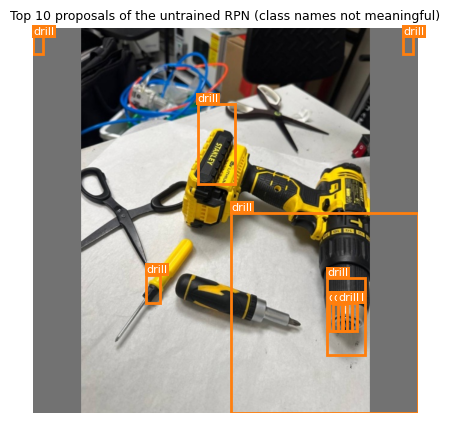

In [64]:
with torch.no_grad():
    proposals, objectness = filter_proposals(rpn_cls, rpn_reg, anchors[0], image.shape[-2:], limit=10)
_, axis = plt.subplots(figsize=(5, 5))
draw_boxes(axis, denormalize(image), proposals.tolist(), [0] * len(proposals), colour="#ff7f0e",
           title="Top 10 proposals of the untrained RPN (class names not meaningful)")
plt.show()

## 6. Evaluation

The same evaluator as the YOLOv2 notebook. Predictions and ground truth are checked strictly (every image needs a
record; boxes inside the canvas; scores in [0, 1]) so nothing is silently dropped.

In [65]:
# workbench_detection/evaluation/records.py
def finite_number(value: Any) -> bool:
    return isinstance(value, (float, int)) and not isinstance(value, bool) and math.isfinite(value)


def mean_or_none(values: Sequence[float]) -> float | None:
    return statistics.mean(values) if values else None


def ratio(numerator: int | float, denominator: int | float) -> float:
    # Explicit zero-denominator convention for P/R/F1. AP has separate null handling.
    return numerator / denominator if denominator else 0.0


def save_json(path: str | Path, value: Any) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n", encoding="utf-8")


def load_json(path: str | Path) -> dict:
    with Path(path).open(encoding="utf-8-sig") as stream:
        result = json.load(stream)
    if not isinstance(result, dict):
        raise ValueError(f"{path}: JSON root must be an object.")
    return result


def write_csv(path: str | Path, rows: list[dict], fields: Sequence[str]) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8-sig") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)


def validate_ground_truth(data: dict) -> dict[str, dict]:
    """Reject malformed data rather than silently dropping images or labels."""
    if data.get("data_kind") not in ("real", "synthetic"):
        raise ValueError("Ground truth must declare data_kind='real' or 'synthetic'.")
    classes = data.get("classes")
    if (not isinstance(classes, list) or not classes
            or any(not isinstance(c, str) or not c.strip() for c in classes)
            or len(set(classes)) != len(classes)):
        raise ValueError("classes must be a nonempty list of unique nonempty strings.")
    images = data.get("images")
    if not isinstance(images, list) or not images:
        raise ValueError("Ground truth images must be a nonempty list.")
    indexed = {}
    for record in images:
        if not isinstance(record, dict):
            raise ValueError("Each ground-truth image must be an object.")
        image_id = record.get("image_id")
        if not isinstance(image_id, str) or not image_id or image_id in indexed:
            raise ValueError("Ground-truth image_id values must be unique nonempty strings.")
        for key in ("width", "height"):
            if not finite_number(record.get(key)) or record[key] <= 0:
                raise ValueError(f"{image_id}: {key} must be positive and finite.")
        if "source" in record and (not isinstance(record["source"], str) or not record["source"]):
            raise ValueError(f"{image_id}: source must be a nonempty string.")
        tags = record.get("tags", [])
        if not isinstance(tags, list) or any(not isinstance(t, str) or not t for t in tags):
            raise ValueError(f"{image_id}: tags must be a list of nonempty strings.")
        _validate_instances(record, record, len(classes), prediction=False)
        indexed[image_id] = record
    return indexed


def _validate_instances(record: dict, image: dict, class_count: int, prediction: bool) -> None:
    image_id = record["image_id"]
    boxes, labels = record.get("boxes"), record.get("labels")
    if not isinstance(boxes, list) or not isinstance(labels, list) or len(boxes) != len(labels):
        raise ValueError(f"{image_id}: boxes and labels must be equal-length lists.")
    for box in boxes:
        if not isinstance(box, list) or len(box) != 4 or not all(finite_number(x) for x in box):
            raise ValueError(f"{image_id}: every box must contain four finite numbers.")
        x1, y1, x2, y2 = box
        if not (0 <= x1 < x2 <= image["width"] and 0 <= y1 < y2 <= image["height"]):
            raise ValueError(f"{image_id}: invalid/out-of-bounds xyxy box {box}.")
    if any(not isinstance(label, int) or isinstance(label, bool)
           or not 0 <= label < class_count for label in labels):
        raise ValueError(f"{image_id}: labels must be integers in [0, {class_count - 1}].")
    if prediction:
        scores = record.get("scores")
        if (not isinstance(scores, list) or len(scores) != len(boxes)
                or any(not finite_number(s) or not 0 <= s <= 1 for s in scores)):
            raise ValueError(f"{image_id}: scores must match boxes and lie in [0, 1].")


def validate_predictions(data: dict, ground_truth: dict) -> dict[str, dict]:
    gt = validate_ground_truth(ground_truth)
    if data.get("data_kind") != ground_truth["data_kind"]:
        raise ValueError("Prediction and ground-truth data_kind must agree.")
    if "classes" in data and data["classes"] != ground_truth["classes"]:
        raise ValueError("Prediction class order differs from ground truth.")
    if not isinstance(data.get("model_name"), str) or not data["model_name"].strip():
        raise ValueError("Prediction JSON must declare a nonempty model_name.")
    if not isinstance(data.get("metadata", {}), dict):
        raise ValueError("Prediction metadata must be an object.")
    if not isinstance(data.get("images"), list):
        raise ValueError("Prediction images must be a list.")
    indexed = {}
    for record in data["images"]:
        if not isinstance(record, dict):
            raise ValueError("Each prediction image must be an object.")
        image_id = record.get("image_id")
        if not isinstance(image_id, str) or image_id not in gt or image_id in indexed:
            raise ValueError(f"Unknown or duplicate prediction image_id: {image_id!r}.")
        _validate_instances(record, gt[image_id], len(ground_truth["classes"]), prediction=True)
        indexed[image_id] = record
    missing = set(gt) - set(indexed)
    if missing:
        raise ValueError(f"Missing predictions for {sorted(missing)}. Supply explicit empty lists for no detections.")
    return indexed


def _canvas_box(box: list[float], name: str, clips: list[dict]) -> list[float]:
    """Clip only <=0.001 pixel export rounding; keep core validation strict."""
    if len(box) != 4 or not all(finite_number(v) for v in box):
        raise ValueError(f"{name}: box must have four finite coordinates.")
    outside = max(0.0, -min(box), max(box) - 640)
    if outside > 0.001:
        raise ValueError(f"{name}: box outside 640x640 by {outside:g} pixels.")
    clipped = [min(640.0, max(0.0, v)) for v in box]
    if clipped != box:
        clips.append({"file_name": name, "before": box, "after": clipped})
    if clipped[0] >= clipped[2] or clipped[1] >= clipped[3]:
        raise ValueError(f"{name}: box has nonpositive area.")
    return clipped


def load_ground_truth(dataset_root: str | Path, split: str = "valid", *,
                              annotation_format: str = "coco", allow_test: bool = False) -> dict:
    """Load one split's ground truth from the dataset folder, cross-checking COCO and YOLO labels.

    COCO and YOLO are cross-checked on EVERY imported image (0.001 px tolerance).
    Default COCO retains annotation precision; choose yolo to reproduce ToolDataset's
    six-decimal decoding. 'contract' contains train images, not a fourth split.
    Test access uses the same explicit allow_test convention as ToolDataset.
    """
    if split not in ("train", "valid", "test", "contract"):
        raise ValueError("Split must be train, valid, test, or contract.")
    if split == "test" and not allow_test:
        raise ValueError("Test is locked. Use allow_test=True / --allow-test only after settings are fixed.")
    if annotation_format not in ("coco", "yolo"):
        raise ValueError("annotation_format must be coco or yolo.")
    root = Path(dataset_root).resolve()
    folder = root / split
    classes = list(CLASSES)
    if (root / "classes.txt").read_text(encoding="utf-8-sig").split() != classes:
        raise ValueError("classes.txt differs from the drill/scissor/screwdriver order.")
    with (root / "manifest.csv").open(encoding="utf-8-sig", newline="") as stream:
        rows = list(csv.DictReader(stream))
    manifest = {}
    for row in rows:
        name = row["file_name"]
        if not name or Path(name).name != name or "\\" in name or name in manifest:
            raise ValueError(f"Invalid or duplicate manifest filename: {name!r}.")
        if row["split"] not in ("train", "valid", "test") or row["origin"] not in ("original", "public"):
            raise ValueError(f"{name}: invalid manifest split/origin.")
        if row["split"] == "test" and row["origin"] != "original":
            raise ValueError("Test manifest must contain originals only.")
        manifest[name] = row
    # Structural evidence only: this cannot establish absence of near-duplicates.
    groups = {}
    for row in rows:
        group = row.get("capture_group")
        if group:
            if group in groups and groups[group] != row["split"]:
                raise ValueError(f"Capture group crosses splits: {group}.")
            groups[group] = row["split"]
    coco_path = folder / "annotations.coco.json"
    coco = load_json(coco_path)
    categories = coco["categories"]
    if (len(categories) != 3 or
            {c["id"]: c["name"] for c in categories} != dict(enumerate(classes, 1))):
        raise ValueError("COCO categories must use IDs 1..3 with the project class names.")
    images, by_id, names = [], {}, set()
    hashes = {}
    for path in (root / "classes.txt", root / "manifest.csv", coco_path):
        hashes[str(path.relative_to(root))] = hashlib.sha256(path.read_bytes()).hexdigest()
    for im in coco["images"]:
        name, coco_id = im["file_name"], im["id"]
        if not isinstance(coco_id, int) or isinstance(coco_id, bool) or coco_id in by_id or name in names:
            raise ValueError("COCO image IDs and filenames must be unique.")
        if name not in manifest or manifest[name]["split"] != ("train" if split == "contract" else split):
            raise ValueError(f"{name}: COCO/manifest split mismatch.")
        if (im["width"], im["height"]) != (640, 640):
            raise ValueError(f"{name}: expected saved 640x640 canvas.")
        if not (folder / "images" / name).is_file():
            raise ValueError(f"{name}: saved image missing.")
        row = manifest[name]
        record = {"image_id": name, "file_name": name, "coco_image_id": coco_id,
                  "width": 640, "height": 640, "boxes": [], "labels": [],
                  "origin": row["origin"], "source": row["source"],
                  "capture_group": row.get("capture_group", ""), "tags": []}
        images.append(record)
        by_id[coco_id] = record
        names.add(name)
    if split != "contract" and names != {r["file_name"] for r in rows if r["split"] == split}:
        raise ValueError("COCO image list differs from the manifest split.")
    clips, annotation_ids = [], set()
    for ann in coco["annotations"]:
        if ann["id"] in annotation_ids or ann["image_id"] not in by_id:
            raise ValueError("Duplicate annotation ID or unknown annotation image.")
        annotation_ids.add(ann["id"])
        if ann.get("iscrowd", 0) or ann.get("ignore", 0):
            raise ValueError("Crowd/ignore annotations need a different evaluation protocol.")
        if ann["category_id"] not in (1, 2, 3):
            raise ValueError("Unknown COCO category ID.")
        bbox = ann["bbox"]
        if len(bbox) != 4 or not all(finite_number(v) for v in bbox) or bbox[2] <= 0 or bbox[3] <= 0:
            raise ValueError("Invalid COCO xywh box.")
        x, y, w, h = bbox
        record = by_id[ann["image_id"]]
        record["boxes"].append(_canvas_box([x, y, x+w, y+h], record["file_name"], clips))
        record["labels"].append(ann["category_id"] - 1)
    max_delta = 0.0
    for record in images:
        name = record["file_name"]
        label_path = folder / "labels" / (Path(name).stem + ".txt")
        hashes[str(label_path.relative_to(root))] = hashlib.sha256(label_path.read_bytes()).hexdigest()
        yolo_boxes, yolo_labels = [], []
        for line in label_path.read_text(encoding="utf-8-sig").splitlines():
            if not line.strip():
                continue
            parts = line.split()
            if len(parts) != 5:
                raise ValueError(f"{name}: expected class cx cy w h in YOLO label.")
            label = int(parts[0])
            cx, cy, w, h = map(float, parts[1:])
            if label not in (0, 1, 2) or not all(finite_number(v) and 0 <= v <= 1 for v in (cx, cy, w, h)) or w <= 0 or h <= 0:
                raise ValueError(f"{name}: invalid YOLO class/normalized box.")
            yolo_boxes.append(_canvas_box([(cx-w/2)*640, (cy-h/2)*640,
                                             (cx+w/2)*640, (cy+h/2)*640], name, clips))
            yolo_labels.append(label)
        remaining = list(zip(yolo_labels, yolo_boxes))
        if len(remaining) != len(record["boxes"]):
            raise ValueError(f"{name}: COCO/YOLO box counts differ.")
        for label, box in zip(record["labels"], record["boxes"]):
            matches = [(max(abs(a-b) for a, b in zip(box, other)), i)
                       for i, (other_label, other) in enumerate(remaining) if label == other_label]
            delta, index = min(matches, default=(float("inf"), -1))
            if delta > 0.001:
                raise ValueError(f"{name}: COCO/YOLO labels or coordinates differ beyond rounding.")
            max_delta = max(max_delta, delta)
            remaining.pop(index)
        for label, class_name in enumerate(classes):
            if record["labels"].count(label) != int(manifest[name][class_name]):
                raise ValueError(f"{name}: manifest class count differs from annotations.")
        if annotation_format == "yolo":
            record.update(boxes=yolo_boxes, labels=yolo_labels)
    gt = {"data_kind": "real", "classes": classes, "images": images,
          "metadata": {"dataset_split": split, "annotation_format": annotation_format,
                       "coordinate_canvas": "saved 640x640 letterboxed pixels",
                       "input_sha256": hashes, "rounding_clips": clips,
                       "coco_yolo_max_delta_pixels": max_delta,
                       "image_root": str(folder / "images")}}
    validate_ground_truth(gt)
    return gt


def _plain_list(value: Any) -> list:
    """Accept Python lists or detached CPU copies of numpy/PyTorch values."""
    if hasattr(value, "detach"):
        value = value.detach().cpu()
    if hasattr(value, "tolist"):
        value = value.tolist()
    if not isinstance(value, list):
        raise ValueError("Expected a list, numpy array, or tensor.")
    return value


def predictions_from_outputs(targets: Sequence[dict], outputs: Sequence[dict],
                             ground_truth: dict, model_name: str, *,
                             label_mapping: Mapping[int, int], metadata: dict | None = None) -> dict:
    """Export decoded, post-NMS pixel xyxy outputs paired with the dataset targets.

    Accumulate ALL batches before calling: missing images are rejected. Pair in the
    actual loader order, using target['file_name'], never batch positions as IDs.
    Mapping is explicit: {0:0,1:1,2:2}, or {1:0,2:1,3:2} if background is reserved.
    Remove background upstream. This does not decode raw YOLO grids or run NMS.
    """
    if len(targets) != len(outputs):
        raise ValueError("One output dictionary is required per target/image.")
    records = []
    for target, output in zip(targets, outputs):
        labels = _plain_list(output["labels"])
        if any(not isinstance(v, int) or isinstance(v, bool) for v in labels):
            raise ValueError("Model labels must be integers.")
        records.append({"image_id": target["file_name"], "boxes": _plain_list(output["boxes"]),
                        "labels": remap_labels(labels, label_mapping),
                        "scores": _plain_list(output["scores"])})
    result = {"data_kind": ground_truth["data_kind"], "model_name": model_name,
              "classes": ground_truth["classes"], "metadata": metadata or {}, "images": records}
    validate_predictions(result, ground_truth)
    return result


# model-specific decoding, NMS and checkpoint loading remain upstream.
def remap_labels(labels: Sequence[int], mapping: Mapping[int, int]) -> list[int]:
    """Example: Faster R-CNN foreground {1:0, 2:1, 3:2}; background must be removed first."""
    try:
        return [mapping[label] for label in labels]
    except KeyError as exc:
        raise ValueError(f"No canonical class mapping for label {exc.args[0]}.") from exc


def undo_letterbox_boxes(boxes: Sequence[Sequence[float]], scale: float,
                         pad_x: float, pad_y: float, width: float,
                         height: float) -> list[list[float]]:
    """Map boxes back to original pixels using ACTUAL preprocessing scale and left/top padding.

    Caller must filter zero-area boxes and corresponding labels/scores after clipping.
    This helper assumes isotropic letterboxing. It does not infer padding/rounding.
    """
    if (not all(finite_number(x) for x in (scale, pad_x, pad_y, width, height))
            or scale <= 0 or width <= 0 or height <= 0):
        raise ValueError("Letterbox scale/dimensions must be positive and finite; padding must be finite.")
    return [[min(width, max(0.0, (b[0] - pad_x) / scale)),
             min(height, max(0.0, (b[1] - pad_y) / scale)),
             min(width, max(0.0, (b[2] - pad_x) / scale)),
             min(height, max(0.0, (b[3] - pad_y) / scale))] for b in boxes]

**Metrics.** AP50 and AP50:95 come from the official COCO evaluator (pycocotools). Precision, recall, F1 and mean
matched IoU are computed at an *operating confidence* chosen on validation. Every false positive is labelled as a
duplicate, wrong class, poor localization or background detection, and every unmatched object as missed.

In [66]:
# workbench_detection/evaluation/metrics.py
@dataclass(frozen=True)
class EvaluationConfig:
    operating_iou: float = 0.50
    operating_confidence: float = 0.50
    # AP uses ALL supplied predictions by default, independently of operating_confidence.
    ap_score_floor: float = 0.0
    ap_ious: tuple[float, ...] = tuple(round(0.5 + 0.05 * i, 2) for i in range(10))
    localization_error_min_iou: float = 0.10
    ap_backend: str = "custom"

    def __post_init__(self) -> None:
        if self.ap_backend not in ("custom", "coco"):
            raise ValueError("ap_backend must be custom or coco.")
        for name in ("operating_iou", "operating_confidence", "ap_score_floor",
                     "localization_error_min_iou"):
            value = getattr(self, name)
            if not finite_number(value) or not 0 <= value <= 1:
                raise ValueError(f"{name} must be a finite number in [0, 1].")
        if self.operating_iou <= 0:
            raise ValueError("operating_iou must be greater than zero.")
        if not 0 < self.localization_error_min_iou < self.operating_iou:
            raise ValueError("localization_error_min_iou must be between 0 and operating_iou.")
        if len(set(self.ap_ious)) != len(self.ap_ious) or not self.ap_ious:
            raise ValueError("ap_ious must be nonempty and unique.")
        if any(not finite_number(x) or not 0 < x <= 1 for x in self.ap_ious):
            raise ValueError("AP IoU thresholds must be in (0, 1].")


def match_class(gt: dict[str, dict], predictions: dict[str, dict], class_id: int,
                iou_threshold: float, score_floor: float) -> dict:
    """Score-ranked, same-class, one-to-one matching. Ties: image_id then input index."""
    candidates = []
    support = 0
    for image_id, image in gt.items():
        support += image["labels"].count(class_id)
        pred = predictions[image_id]
        for index, (label, score) in enumerate(zip(pred["labels"], pred["scores"])):
            if label == class_id and score >= score_floor:
                candidates.append((image_id, index, score))
    candidates.sort(key=lambda item: (-item[2], item[0], item[1]))
    used: dict[str, set[int]] = {image_id: set() for image_id in gt}
    rows = []
    for image_id, pred_index, score in candidates:
        image = gt[image_id]
        box = predictions[image_id]["boxes"][pred_index]
        eligible = [(pair_iou(box, gt_box), gt_index)
                    for gt_index, (gt_box, label) in enumerate(zip(image["boxes"], image["labels"]))
                    if label == class_id and gt_index not in used[image_id]]
        best_iou, best_index = max(eligible, key=lambda item: (item[0], -item[1]), default=(0.0, -1))
        is_tp = best_index >= 0 and best_iou >= iou_threshold
        if is_tp:
            used[image_id].add(best_index)
        rows.append({"image_id": image_id, "prediction_index": pred_index,
                     "class_id": class_id, "score": score, "tp": int(is_tp),
                     "fp": int(not is_tp), "ground_truth_index": best_index if is_tp else None,
                     "matched_iou": best_iou if is_tp else None})
    return {"support": support, "rows": rows, "used_ground_truth": used}


def precision_recall_curve(matching: dict) -> dict:
    tp = fp = 0
    precision, recall, scores = [], [], []
    for row in matching["rows"]:
        tp += row["tp"]
        fp += row["fp"]
        precision.append(ratio(tp, tp + fp))
        recall.append(ratio(tp, matching["support"]))
        scores.append(row["score"])
    return {"precision": precision, "recall": recall, "scores": scores}


def average_precision_101(curve: dict, support: int) -> float | None:
    """Mean interpolated precision at recalls 0.00, 0.01, ..., 1.00."""
    if support == 0:
        return None
    recalls, precisions = curve["recall"], curve["precision"]
    envelope = list(precisions)
    for index in range(len(envelope) - 2, -1, -1):
        envelope[index] = max(envelope[index], envelope[index + 1])
    total = 0.0
    pointer = 0
    for step in range(101):
        target = step / 100
        while pointer < len(recalls) and recalls[pointer] < target:
            pointer += 1
        total += envelope[pointer] if pointer < len(envelope) else 0.0
    return total / 101


def coco_ap(ground_truth: dict, predictions: dict, config: EvaluationConfig) -> tuple[list[dict], dict]:
    """Compute official COCO bbox AP for all areas, with maxDets=100."""
    try:
        from pycocotools.coco import COCO
        from pycocotools.cocoeval import COCOeval
    except ImportError as exc:
        raise ValueError("Project AP requires pycocotools. Install it with python -m pip install pycocotools.") from exc
    gt = validate_ground_truth(ground_truth)
    pred = validate_predictions(predictions, ground_truth)
    categories = [{"id": i + 1, "name": name} for i, name in enumerate(ground_truth["classes"])]
    images, annotations, detections = [], [], []

    def xywh(box: list) -> list:
        x1, y1, x2, y2 = box
        return [x1, y1, x2 - x1, y2 - y1]

    # Stable image IDs keep confidence ties reproducible.
    for image_id, name in enumerate(sorted(gt), 1):
        image = gt[name]
        images.append({"id": image_id, "width": image["width"], "height": image["height"]})
        for box, label in zip(image["boxes"], image["labels"]):
            bbox = xywh(box)
            annotations.append({"id": len(annotations) + 1, "image_id": image_id,
                                "category_id": label + 1, "bbox": bbox,
                                "area": bbox[2] * bbox[3], "iscrowd": 0})
        record = pred[name]
        for box, label, score in zip(record["boxes"], record["labels"], record["scores"]):
            if score >= config.ap_score_floor:
                detections.append({"image_id": image_id, "category_id": label + 1,
                                   "bbox": xywh(box), "score": score})

    with redirect_stdout(StringIO()):
        reference = COCO()
        reference.dataset = {"info": {}, "images": images, "categories": categories,
                             "annotations": annotations}
        reference.createIndex()
        # COCO.loadRes expects at least one detection.
        if detections:
            detected = reference.loadRes(detections)
        else:
            detected = COCO()
            detected.dataset = {**reference.dataset, "annotations": []}
            detected.createIndex()
        evaluator = COCOeval(reference, detected, "bbox")
        evaluator.evaluate()
        evaluator.accumulate()

    # Axes: IoU, recall sample, category, area range, maxDets.
    precision = evaluator.eval["precision"][:, :, :, 0, -1]
    scores = evaluator.eval["scores"][0, :, :, 0, -1]
    aps, curves = [], {}
    for index, name in enumerate(ground_truth["classes"]):
        class_ap = {}
        for iou, row in zip(evaluator.params.iouThrs, precision[:, :, index]):
            valid = row[row >= 0]
            class_ap[f"{iou:.2f}"] = float(valid.mean()) if valid.size else None
        aps.append(class_ap)
        valid = precision[0, :, index] >= 0
        curves[name] = {"precision": precision[0, valid, index].tolist(),
                        "recall": evaluator.params.recThrs[valid].tolist(),
                        "scores": scores[valid, index].tolist()}
    return aps, curves


def evaluate_model(ground_truth: dict, predictions: dict,
                   config: EvaluationConfig | None = None) -> dict:
    """Evaluate already postprocessed detections. Never tunes settings or calls a detector."""
    config = config or EvaluationConfig()
    gt = validate_ground_truth(ground_truth)
    pred = validate_predictions(predictions, ground_truth)
    per_class, all_operating_rows, all_ious = [], [], []
    official_aps, curves = coco_ap(ground_truth, predictions, config) if config.ap_backend == "coco" else (None, {})
    for class_id, name in enumerate(ground_truth["classes"]):
        if official_aps is not None:
            aps = official_aps[class_id]
        else:
            aps = {}
            for threshold in sorted(set(config.ap_ious) | {0.50}):
                matching = match_class(gt, pred, class_id, threshold, config.ap_score_floor)
                curve = precision_recall_curve(matching)
                aps[f"{threshold:.2f}"] = average_precision_101(curve, matching["support"])
                if threshold == 0.50:
                    curves[name] = curve
        operating = match_class(gt, pred, class_id, config.operating_iou, config.operating_confidence)
        rows = operating["rows"]
        tp, fp = sum(r["tp"] for r in rows), sum(r["fp"] for r in rows)
        fn = operating["support"] - tp
        precision, recall = ratio(tp, tp + fp), ratio(tp, tp + fn)
        ious = [r["matched_iou"] for r in rows if r["tp"]]
        all_ious.extend(ious)
        all_operating_rows.extend(rows)
        per_class.append({"class_id": class_id, "class_name": name,
                          "ground_truth_instances": operating["support"],
                          "predictions_at_operating_threshold": tp + fp,
                          "tp": tp, "fp": fp, "fn": fn,
                          "precision": precision, "recall": recall,
                          "f1": ratio(2 * precision * recall, precision + recall),
                          "ap50": aps["0.50"],
                          "ap_iou_average": mean_or_none([aps[f"{t:.2f}"] for t in config.ap_ious
                                                   if aps[f"{t:.2f}"] is not None]),
                          "ap_by_iou": aps, "mean_matched_iou": mean_or_none(ious)})
    tp = sum(c["tp"] for c in per_class)
    fp = sum(c["fp"] for c in per_class)
    fn = sum(c["fn"] for c in per_class)
    p, r = ratio(tp, tp + fp), ratio(tp, tp + fn)
    standard_grid = tuple(round(0.5 + 0.05 * i, 2) for i in range(10))
    result = {
        "model_name": predictions["model_name"], "data_kind": ground_truth["data_kind"],
        "model_metadata": predictions.get("metadata", {}), "config": asdict(config),
        "metric_method": ("pycocotools COCO bbox AP, all areas, maxDets=100" if official_aps is not None
                          else "Custom 101-point interpolated AP"),
        "iou_average_is_standard_50_95": tuple(sorted(config.ap_ious)) == standard_grid,
        "image_count": len(gt), "ground_truth_instances": tp + fn,
        "supplied_predictions": sum(len(x["boxes"]) for x in pred.values()),
        "evaluated_ap_predictions": sum(sum(s >= config.ap_score_floor for s in x["scores"]) for x in pred.values()),
        "classes_with_ground_truth": [c["class_name"] for c in per_class if c["ground_truth_instances"]],
        "map50": mean_or_none([c["ap50"] for c in per_class if c["ap50"] is not None]),
        "map_iou_average": mean_or_none([c["ap_iou_average"] for c in per_class if c["ap_iou_average"] is not None]),
        "precision_micro": p, "recall_micro": r, "f1_micro": ratio(2 * p * r, p + r),
        "tp": tp, "fp": fp, "fn": fn, "mean_matched_iou": mean_or_none(all_ious),
        "per_class": per_class, "pr_curves_at_iou_0.50": curves,
        "operating_matches": all_operating_rows,
    }
    result["error_records"] = analyse_errors(ground_truth, predictions, result, config)
    return result


def analyse_errors(ground_truth: dict, predictions: dict, result: dict,
                   config: EvaluationConfig) -> list[dict]:
    """Mutually exclusive descriptive FP labels, NOT experimentally established causes.

    Priority: same-class overlap >= operating IoU -> duplicate;
    other-class overlap >= operating IoU -> wrong_class;
    same-class overlap >= diagnostic minimum -> localization; otherwise background.
    Wrong-class detections also leave a FN for their unmatched GT object.
    """
    gt = {x["image_id"]: x for x in ground_truth["images"]}
    pred = {x["image_id"]: x for x in predictions["images"]}
    matched = set()
    records = []
    for row in result["operating_matches"]:
        image_id, index = row["image_id"], row["prediction_index"]
        image = gt[image_id]
        if row["tp"]:
            matched.add((image_id, row["ground_truth_index"]))
            continue
        box = pred[image_id]["boxes"][index]
        overlaps = [(pair_iou(box, b), i) for i, b in enumerate(image["boxes"])]
        same = [x for x in overlaps if image["labels"][x[1]] == row["class_id"]]
        other = [x for x in overlaps if image["labels"][x[1]] != row["class_id"]]
        best_same = max(same, default=(0.0, -1))
        best_other = max(other, default=(0.0, -1))
        if best_same[0] >= config.operating_iou:
            category, evidence = "duplicate", best_same
        elif best_other[0] >= config.operating_iou:
            category, evidence = "wrong_class", best_other
        elif best_same[0] >= config.localization_error_min_iou:
            category, evidence = "localization", best_same
        else:
            category, evidence = "background_or_low_overlap", max(overlaps, default=(0.0, -1))
        records.append({"image_id": image_id, "kind": "false_positive", "category": category,
                        "prediction_index": index, "predicted_class": ground_truth["classes"][row["class_id"]],
                        "score": row["score"], "related_ground_truth_index": evidence[1] if evidence[1] >= 0 else None,
                        "overlap_iou": evidence[0], "source": image.get("source", "unknown"),
                        "tags": ";".join(image.get("tags", []))})
    for image_id, image in gt.items():
        for index, label in enumerate(image["labels"]):
            if (image_id, index) not in matched:
                records.append({"image_id": image_id, "kind": "false_negative", "category": "missed_object",
                                "ground_truth_index": index, "ground_truth_class": ground_truth["classes"][label],
                                "source": image.get("source", "unknown"), "tags": ";".join(image.get("tags", []))})
    return records


def evaluate_subsets(ground_truth: dict, predictions: dict, config: EvaluationConfig, *,
                     origins_only: bool = False) -> dict:
    """Metrics for each image origin (original/public), and optionally each source and tag."""
    groups: dict[str, list[str]] = {}
    for image in ground_truth["images"]:
        if image.get("origin"):
            groups.setdefault("origin:" + image["origin"], []).append(image["image_id"])
        if origins_only:
            continue
        if image.get("source"):
            groups.setdefault("source:" + image["source"], []).append(image["image_id"])
        for tag in set(image.get("tags", [])):
            groups.setdefault("tag:" + tag, []).append(image["image_id"])
    results = {}
    for name, ids in sorted(groups.items()):
        selected = set(ids)
        subset_gt = {**ground_truth, "images": [x for x in ground_truth["images"] if x["image_id"] in selected]}
        subset_pred = {**predictions, "images": [x for x in predictions["images"] if x["image_id"] in selected]}
        evaluation = evaluate_model(subset_gt, subset_pred, config)
        results[name] = {key: evaluation[key] for key in (
            "image_count", "ground_truth_instances", "classes_with_ground_truth", "map50",
            "map_iou_average", "precision_micro", "recall_micro", "f1_micro", "tp", "fp", "fn", "per_class")}
    return results

**Protocol.** On validation, the detector exports predictions at each RPN NMS IoU in the proposal's grid for
Faster R-CNN (0.50 / 0.70, with the final class-wise NMS fixed at 0.50); the best AP50 wins, and the operating
confidence (0.2 / 0.3 / 0.4) is the one with the best F1. These are frozen in `evaluation_protocol.json`, which is
the only way to score the test split.

In [67]:
# workbench_detection/evaluation/protocol.py
CONFIDENCE_GRID = (0.20, 0.30, 0.40)                                # proposal section 4.2
NMS_GRIDS = {"faster_rcnn": (0.50, 0.70), "yolov2": (0.45, 0.50, 0.60)}


def select_operating_confidence(ground_truth: dict, predictions: dict) -> tuple[float, list[dict]]:
    """Maximize validation micro-F1 at IoU 0.50. Prefer higher confidence on a tie."""
    gt = validate_ground_truth(ground_truth)
    pred = validate_predictions(predictions, ground_truth)
    trials = []
    for confidence in CONFIDENCE_GRID:
        tp = fp = fn = 0
        for class_id in range(len(ground_truth["classes"])):
            matching = match_class(gt, pred, class_id, 0.50, confidence)
            hits = sum(row["tp"] for row in matching["rows"])
            tp += hits
            fp += len(matching["rows"]) - hits
            fn += matching["support"] - hits
        trials.append({"confidence": confidence, "micro_f1": ratio(2 * tp, 2 * tp + fp + fn),
                       "tp": tp, "fp": fp, "fn": fn})
    winner = max(trials, key=lambda row: (row["micro_f1"], row["confidence"]))
    return winner["confidence"], trials


def select_nms_exports(ground_truth: dict, exports: list[dict], config: EvaluationConfig) -> tuple[list[dict], dict]:
    """Rank validation exports produced by the detector at each proposed NMS IoU."""
    groups = {}
    for export in exports:
        groups.setdefault(export["model_name"], []).append(export)
    winners, trials = [], {}
    for name, candidates in groups.items():
        settings = [candidate.get("metadata", {}) for candidate in candidates]
        family = settings[0].get("model_family")
        if family not in NMS_GRIDS:
            raise ValueError(f"{name}: model_family must be faster_rcnn or yolov2.")
        if any(meta.get("model_family") != family for meta in settings):
            raise ValueError(f"{name}: inconsistent model family across NMS candidates.")
        for field in ("checkpoint", "nms_stage", "nms_rule"):
            if not settings[0].get(field) or any(meta.get(field) != settings[0][field] for meta in settings):
                raise ValueError(f"{name}: keep {field} fixed across NMS candidates and record it.")
        for field in ("export_score_floor", "final_nms_iou"):
            if field == "final_nms_iou" and settings[0]["nms_stage"] == "final":
                continue
            if any(meta.get(field) != settings[0].get(field) for meta in settings):
                raise ValueError(f"{name}: keep {field} fixed across NMS candidates.")
        floor = settings[0].get("export_score_floor")
        if not finite_number(floor) or not 0 <= floor <= config.ap_score_floor:
            raise ValueError(f"{name}: record the shared export_score_floor at or below the AP floor.")
        if family == "yolov2" and settings[0]["nms_stage"] != "final":
            raise ValueError(f"{name}: YOLOv2 sweeps final detection NMS.")
        thresholds = [meta.get("nms_iou") for meta in settings]
        grid = NMS_GRIDS[family]
        if len(thresholds) != len(grid) or set(thresholds) != set(grid):
            raise ValueError(f"{name}: supply one export for each NMS IoU in {grid}.")
        rows = []
        for candidate, threshold in zip(candidates, thresholds):
            aps, _ = coco_ap(ground_truth, candidate, config)
            ap50 = mean_or_none([row["0.50"] for row in aps if row["0.50"] is not None])
            ap5095 = mean_or_none([value for row in aps for value in row.values() if value is not None])
            if ap50 is None:
                raise ValueError("NMS selection requires validation ground truth with objects.")
            rows.append({"nms_iou": threshold, "map50": ap50, "map_iou_average": ap5095})
        winner = max(range(len(rows)), key=lambda i: (rows[i]["map50"], rows[i]["map_iou_average"],
                                                       -rows[i]["nms_iou"]))
        winners.append(candidates[winner])
        trials[name] = rows
    return winners, trials


def run_evaluation(ground_truth: dict, predictions_list: list[dict], output_dir: str | Path,
                   config: EvaluationConfig | None = None, *, split: str = "validation",
                   image_root: str | Path | None = None, include_subsets: bool = True,
                   evaluation_purpose: str = "model_evaluation",
                   project_protocol: bool = False, select_nms: bool = False,
                   frozen_protocol: dict | None = None, detailed: bool = False,
                   results_dir: str | Path | None = None) -> list[dict]:
    """Write report metrics and figures separately from protocol and diagnostic files."""
    config = config or EvaluationConfig(ap_score_floor=0.001 if project_protocol else 0.0)
    validate_ground_truth(ground_truth)
    if split not in ("train", "contract", "valid", "validation", "test"):
        raise ValueError("Invalid declared evaluation split.")
    if evaluation_purpose not in ("model_evaluation", "software_check"):
        raise ValueError("Invalid evaluation purpose.")
    imported_split = ground_truth.get("metadata", {}).get("dataset_split")
    if imported_split and imported_split != ("valid" if split == "validation" else split):
        raise ValueError("Declared split differs from the loaded ground-truth split.")
    if evaluation_purpose == "software_check" and split == "test":
        raise ValueError("Software checks must use development data.")
    if not predictions_list:
        raise ValueError("At least one prediction set is required.")
    names = [p.get("model_name") for p in predictions_list]
    for pred in predictions_list:
        validate_predictions(pred, ground_truth)
        if pred.get("metadata", {}).get("prediction_kind") == "software_fixture" and evaluation_purpose != "software_check":
            raise ValueError("Fabricated software fixtures require evaluation_purpose='software_check'.")
    if len(set(names)) != len(names) and not select_nms:
        raise ValueError("Model names must be unique within a comparison.")
    protocol = None
    if project_protocol:
        if ground_truth["data_kind"] != "real" or evaluation_purpose != "model_evaluation":
            raise ValueError("The project protocol requires real evaluation inputs.")
        if split not in ("valid", "validation", "test"):
            raise ValueError("Use validation or test for the project protocol.")
        if not include_subsets:
            raise ValueError("The project protocol includes origin breakdowns.")
        if split == "test" and (select_nms or frozen_protocol is None):
            raise ValueError("Final test requires a frozen validation protocol and cannot select NMS.")
        if split != "test" and frozen_protocol is not None:
            raise ValueError("Use a frozen protocol only for final testing.")
        config = EvaluationConfig(ap_backend="coco", ap_score_floor=config.ap_score_floor)
        protocol = {"version": 1, "selected_on": "validation", "ap_backend": "coco",
                    "ap_score_floor": config.ap_score_floor, "matching_iou": 0.50,
                    "models": {}, "nms_trials": {}}
        if split == "test":
            if len(ground_truth["images"]) != 50 or any(im.get("origin") != "original" for im in ground_truth["images"]):
                raise ValueError("Final test requires exactly 50 images marked as original.")
            if (frozen_protocol.get("version"), frozen_protocol.get("selected_on"),
                frozen_protocol.get("ap_backend"), frozen_protocol.get("matching_iou")) != (1, "validation", "coco", 0.50):
                raise ValueError("Invalid frozen validation protocol.")
            config = replace(config, ap_score_floor=frozen_protocol["ap_score_floor"])
            if set(frozen_protocol["models"]) != set(names):
                raise ValueError("Test model names must match the frozen validation protocol.")
            protocol = frozen_protocol
        elif select_nms:
            predictions_list, protocol["nms_trials"] = select_nms_exports(ground_truth, predictions_list, config)

        final_rules = {pred.get("metadata", {}).get("nms_rule") for pred in predictions_list}
        if final_rules != {"class_aware"}:
            raise ValueError("Record metadata.nms_rule='class_aware' for final detection NMS.")
        for pred in predictions_list:
            name = pred["model_name"]
            meta = pred.get("metadata", {})
            nms = {key: meta.get(key) for key in ("nms_iou", "nms_stage", "nms_rule", "final_nms_iou")}
            if (not finite_number(nms["nms_iou"]) or not 0 < nms["nms_iou"] <= 1
                    or nms["nms_stage"] not in ("rpn", "final")):
                raise ValueError(f"{name}: record nms_iou and nms_stage ('rpn' or 'final').")
            if nms["nms_stage"] == "final":
                if nms["final_nms_iou"] is not None and nms["final_nms_iou"] != nms["nms_iou"]:
                    raise ValueError(f"{name}: conflicting final NMS thresholds.")
                nms["final_nms_iou"] = nms["nms_iou"]
            if not finite_number(nms["final_nms_iou"]) or not 0 < nms["final_nms_iou"] <= 1:
                raise ValueError(f"{name}: record final_nms_iou when sweeping RPN NMS.")
            floor = meta.get("export_score_floor")
            if not finite_number(floor) or not 0 <= floor <= config.ap_score_floor:
                raise ValueError(f"{name}: record export_score_floor at or below the AP floor.")
            if split == "test":
                saved = protocol["models"][name]
                if saved["nms"] != nms or saved["operating_confidence"] not in CONFIDENCE_GRID:
                    raise ValueError(f"{name}: test settings differ from the frozen validation protocol.")
            else:
                confidence, trials = select_operating_confidence(ground_truth, pred)
                protocol["models"][name] = {"operating_confidence": confidence,
                                            "confidence_trials": trials, "nms": nms,
                                            "validation_checkpoint": meta.get("checkpoint")}
    elif select_nms or frozen_protocol is not None:
        raise ValueError("NMS selection and frozen settings require the project protocol.")
    model_confidences = {name: settings["operating_confidence"]
                         for name, settings in protocol["models"].items()} if protocol else {}
    output = Path(output_dir)
    if results_dir is not None:
        work, report_path = output.resolve(), Path(results_dir).resolve()
        if work.is_relative_to(report_path) or report_path.is_relative_to(work):
            raise ValueError("Report and diagnostic directories must be separate.")
    output.mkdir(parents=True, exist_ok=True)
    results = []
    synthetic = ground_truth["data_kind"] == "synthetic"
    banner = "SYNTHETIC TEST DATA - NOT PROJECT RESULTS" if synthetic else f"REAL DATA - declared split: {split}"
    if evaluation_purpose == "software_check":
        banner = "SOFTWARE CHECK - NOT DETECTOR RESULTS"
    if not detailed or results_dir is not None:
        report = Path(results_dir) if results_dir is not None else output
        report.mkdir(parents=True, exist_ok=True)
        print(banner)
        summaries = [banner]
        good, bad = [], []
        for index, predictions in enumerate(predictions_list, 1):
            model_config = replace(config, operating_confidence=model_confidences.get(
                predictions["model_name"], config.operating_confidence))
            result = evaluate_model(ground_truth, predictions, model_config)
            result["declared_split"] = split
            result["subsets"] = evaluate_subsets(ground_truth, predictions, model_config, origins_only=True) if include_subsets else {}
            results.append(result)
            with redirect_stdout(StringIO()) as summary:
                print_metrics(result)
            rendered = summary.getvalue().strip()
            print(f"\n{rendered}")
            summaries.append(rendered)
            curves = result["pr_curves_at_iou_0.50"]
            plot_curves({name: list(zip(curve["recall"], curve["precision"])) for name, curve in curves.items()},
                        report / f"model_{index:02d}_precision_recall.svg",
                        f"{banner} | {result['model_name']} | IoU 0.50",
                        "Recall", "Precision", unit_axes=True)
            bad.extend(row["image_id"] for row in result["error_records"])
            good.extend(row["image_id"] for row in result["operating_matches"] if row["tp"])
        # Select at most one clean success and two distinct examples with errors.
        errors = list(dict.fromkeys(bad))
        error_ids = set(errors)
        clean = next((image_id for image_id in good if image_id not in error_ids), None)
        examples = ([clean] if clean else []) + errors[:2]
        if not examples:
            examples = [ground_truth["images"][0]["image_id"]]
        selected = set(examples)
        if protocol:
            save_json(output / "evaluation_protocol.json", protocol)
            for name, trials in protocol["nms_trials"].items():
                print(f"{name} NMS trials: " + ", ".join(
                    f"{row['nms_iou']:.2f}: AP50={row['map50']:.4f}" for row in trials))
        save_prediction_gallery(
            {**ground_truth, "images": [im for im in ground_truth["images"] if im["image_id"] in selected]},
            [{**p, "images": [im for im in p["images"] if im["image_id"] in selected]} for p in predictions_list],
            report / "examples", config, image_root, model_confidences=model_confidences)
        (report / "metrics.txt").write_text("\n\n".join(summaries) + "\n", encoding="utf-8")
        print(f"Report metrics and figures: {report.resolve()}")
        if not detailed:
            return results
        results.clear()

    summary_rows, subset_rows = [], []
    manifest = {"generated_utc": datetime.now(timezone.utc).isoformat(), "data_kind": ground_truth["data_kind"],
                "evaluation_purpose": evaluation_purpose, "ground_truth_metadata": ground_truth.get("metadata", {}),
                "declared_split": split, "config": asdict(config), "classes": ground_truth["classes"],
                "image_ids": [x["image_id"] for x in ground_truth["images"]],
                "models": [], "note": "Split integrity, checkpoint provenance and training leakage require external verification."}
    for index, predictions in enumerate(predictions_list, 1):
        model_config = replace(config, operating_confidence=model_confidences.get(
            predictions["model_name"], config.operating_confidence))
        result = evaluate_model(ground_truth, predictions, model_config)
        result["evaluation_purpose"] = evaluation_purpose
        result["declared_split"] = split
        result["subsets"] = evaluate_subsets(ground_truth, predictions, model_config) if include_subsets else {}
        results.append(result)
        model_dir = output / f"model_{index:02d}"
        save_json(model_dir / "metrics.json", result)
        write_csv(model_dir / "per_class.csv", result["per_class"], [
            "class_id", "class_name", "ground_truth_instances", "predictions_at_operating_threshold",
            "tp", "fp", "fn", "precision", "recall", "f1", "ap50", "ap_iou_average", "mean_matched_iou"])
        write_csv(model_dir / "errors.csv", result["error_records"], [
            "image_id", "kind", "category", "prediction_index", "predicted_class", "score",
            "related_ground_truth_index", "overlap_iou", "ground_truth_index", "ground_truth_class", "source", "tags"])
        for name, curve in result["pr_curves_at_iou_0.50"].items():
            class_index = ground_truth["classes"].index(name)
            write_csv(model_dir / f"pr_class_{class_index}.csv", [dict(zip(("score", "precision", "recall"), values))
                      for values in zip(curve["scores"], curve["precision"], curve["recall"])], ["score", "precision", "recall"])
        plot_curves({name: list(zip(curve["recall"], curve["precision"]))
                     for name, curve in result["pr_curves_at_iou_0.50"].items()}, model_dir / "pr_curves.svg",
                    f'{banner}: {predictions["model_name"]}', "Recall", "Precision", unit_axes=True)
        summary = {key: result[key] for key in ("model_name", "image_count", "ground_truth_instances", "map50",
                   "map_iou_average", "precision_micro", "recall_micro", "f1_micro", "tp", "fp", "fn", "mean_matched_iou")}
        # attach measured integration metadata in these optional keys.
        # Blank cells mean NOT MEASURED; no timings or sizes are fabricated.
        metadata = predictions.get("metadata", {})
        benchmark = metadata.get("benchmark", {})
        size = metadata.get("model_size", {})
        if not isinstance(benchmark, dict) or not isinstance(size, dict):
            raise ValueError("metadata.benchmark and metadata.model_size must be objects.")
        summary.update(data_kind=ground_truth["data_kind"], evaluation_purpose=evaluation_purpose, split=split,
                       operating_confidence=model_config.operating_confidence, ap_backend=config.ap_backend,
                       mean_latency_ms=benchmark.get("mean_latency_ms"),
                       sequential_fps=benchmark.get("sequential_fps"),
                       device=benchmark.get("device"), precision=benchmark.get("precision"), timed_scope=benchmark.get("timed_scope"),
                       parameter_count=size.get("parameter_count"),
                       checkpoint_file_bytes=size.get("checkpoint_file_bytes"))
        summary_rows.append(summary)
        for subset_name, subset in result["subsets"].items():
            subset_rows.append({"model_name": result["model_name"], "subset": subset_name,
                               **{k: subset[k] for k in ("image_count", "ground_truth_instances", "map50", "map_iou_average", "precision_micro", "recall_micro")},
                               "classes_with_ground_truth": ";".join(subset["classes_with_ground_truth"])})
        manifest["models"].append({"model_name": result["model_name"], "directory": model_dir.name,
                                   "metadata": predictions.get("metadata", {})})
    write_csv(output / "comparison.csv", summary_rows, list(summary_rows[0]))
    write_csv(output / "subsets.csv", subset_rows, ["model_name", "subset", "image_count", "ground_truth_instances",
              "classes_with_ground_truth", "map50", "map_iou_average", "precision_micro", "recall_micro"])
    if protocol:
        manifest["project_protocol"] = protocol
        save_json(output / "evaluation_protocol.json", protocol)
    save_json(output / "run_manifest.json", manifest)
    # Snapshot exact inputs so plots/tables can be regenerated without another inference run.
    save_json(output / "ground_truth_snapshot.json", ground_truth)
    for index, predictions in enumerate(predictions_list, 1):
        save_json(output / f"predictions_{index:02d}_snapshot.json", predictions)
    plot_ap_comparison(results, ground_truth["classes"], output / "ap_comparison.svg", banner)
    save_prediction_gallery(ground_truth, predictions_list, output / "gallery", config, image_root,
                            model_confidences=model_confidences)
    links = ["comparison.csv", "subsets.csv", "run_manifest.json", "ground_truth_snapshot.json"]
    if protocol:
        links.append("evaluation_protocol.json")
    body = ["<!doctype html><html><head><meta charset='utf-8'><title>Evaluation report</title>",
            "<style>body{font:16px Arial;max-width:1300px;margin:30px auto;padding:20px}img{max-width:100%}h1{color:#923414}</style></head><body>",
            f"<h1>{escape(banner)}</h1>",
            ("<p>Real training annotations with fabricated detections. This checks the software, not detector accuracy.</p>"
             if evaluation_purpose == "software_check" else ""),
            f'<p>{escape(results[0]["metric_method"])}. IoU grid: 0.50:0.05:0.95.</p>',
            f"<p>Operating IoU: {config.operating_iou}; AP score floor: {config.ap_score_floor}.</p>",
            "<p>AP uses supplied score-ranked predictions, independently of the operating confidence. Earlier model filtering can still truncate AP.</p>",
            "<p>AP is N/A for classes without ground truth; they are excluded from mAP. P/R/F1 use zero for zero denominators.</p>",
            "<p>Source/tag subsets may overlap and have different supported classes. Check counts before comparing their mAP.</p>",
            "<ul>" + "".join(f'<li><a href="{link}">{link}</a></li>' for link in links) + "</ul>",
            '<h2>Per-class AP comparison</h2><img src="ap_comparison.svg" alt="Per-class AP">']
    for index, result in enumerate(results, 1):
        body.append(f'<h2>{escape(result["model_name"])}</h2>'
                    f'<p>Operating confidence: {result["config"]["operating_confidence"]:g}</p><p><a href="model_{index:02d}/metrics.json">Metrics JSON</a> | '
                    f'<a href="model_{index:02d}/per_class.csv">Per-class CSV</a> | <a href="model_{index:02d}/errors.csv">Error records</a></p>'
                    f'<img src="model_{index:02d}/pr_curves.svg" alt="Precision recall curves">')
    body.append("<h2>Same-image comparisons</h2><p>Coordinate-only diagrams unless image_root was supplied. Diagnostic error categories are descriptions, not proven failure causes.</p>")
    for index, image in enumerate(ground_truth["images"], 1):
        body.append(f'<h3>{escape(image["image_id"])}</h3><img src="gallery/image_{index:03d}.svg" alt="Ground truth and model predictions">')
    (output / "index.html").write_text("\n".join(body + ["</body></html>"]), encoding="utf-8")
    return results

In [68]:
# workbench_detection/evaluation/report.py — saved figures and printed summaries
# SVG figures are generated directly so plotting needs no external packages.
def _svg_start(width: int, height: int, title: str) -> list[str]:
    return [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
            '<rect width="100%" height="100%" fill="white"/>',
            '<style>text{font-family:Arial,sans-serif;font-size:13px} .title{font-size:17px;font-weight:bold}</style>',
            f'<text x="24" y="28" class="title">{escape(title)}</text>']


def _save_svg(path: str | Path, elements: list[str]) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text("\n".join(elements + ["</svg>"]), encoding="utf-8")


def plot_curves(series: dict[str, list[tuple[float, float]]], path: str | Path,
                title: str, x_label: str, y_label: str, *, unit_axes: bool = False) -> None:
    """Simple labelled line chart. Missing history values should be omitted, not fabricated."""
    width, height = 1000, 570
    left, top, plot_w, plot_h = 75, 65, 570, 410
    elements = _svg_start(width, height, title)
    points = [point for values in series.values() for point in values]
    x_max = 1.0 if unit_axes else max([p[0] for p in points] + [1.0])
    y_max = 1.0 if unit_axes else max([p[1] for p in points] + [0.01]) * 1.05
    for step in range(6):
        fraction = step / 5
        x, y = left + fraction * plot_w, top + plot_h * (1 - fraction)
        elements.extend([f'<path d="M{x},{top} V{top + plot_h} M{left},{y} H{left + plot_w}" stroke="#e4e7eb" fill="none"/>',
                         f'<text x="{x}" y="{top + plot_h + 24}" text-anchor="middle">{fraction * x_max:.2g}</text>',
                         f'<text x="{left - 10}" y="{y + 4}" text-anchor="end">{fraction * y_max:.2g}</text>'])
    colors = ("#1764ab", "#cc4d16", "#228644", "#864ba8", "#946f00", "#007e87")
    for index, (name, values) in enumerate(series.items()):
        color = colors[index % len(colors)]
        points_string = " ".join(f"{left + x / x_max * plot_w:.2f},{top + (1 - y / y_max) * plot_h:.2f}" for x, y in values)
        elements.append(f'<polyline points="{points_string}" fill="none" stroke="{color}" stroke-width="2"/>')
        legend_y = 80 + index * 24
        elements.extend([f'<path d="M680,{legend_y} h24" stroke="{color}" stroke-width="3"/>',
                         f'<text x="713" y="{legend_y + 4}">{escape(name)}</text>'])
    elements.extend([f'<text x="360" y="530" text-anchor="middle">{escape(x_label)}</text>',
                     f'<text transform="translate(20,280) rotate(-90)" text-anchor="middle">{escape(y_label)}</text>'])
    _save_svg(path, elements)


def plot_training_history(history: Sequence[dict], output_dir: str | Path,
                          model_name: str = "MODEL_NAME_PLACEHOLDER") -> None:
    """Rows use epoch/train_loss/val_loss/val_map50; losses are optional.

    Loss magnitudes across different detector architectures are not directly comparable.
    History is supplied by teammates, not invented by this evaluator.
    """
    for row in history:
        if not finite_number(row.get("epoch")) or row["epoch"] < 0:
            raise ValueError("History rows require a finite nonnegative epoch.")
        for key in ("train_loss", "val_loss", "val_map50"):
            if row.get(key) is not None:
                if not finite_number(row[key]) or row[key] < 0 or (key == "val_map50" and row[key] > 1):
                    raise ValueError(f"Invalid history value for {key}.")
    if len({row["epoch"] for row in history}) != len(history):
        raise ValueError("Duplicate epochs in training history.")
    ordered = sorted(history, key=lambda row: row["epoch"])
    loss_series = {key: [(row["epoch"], row[key]) for row in ordered if row.get(key) is not None]
                   for key in ("train_loss", "val_loss")}
    loss_series = {key: values for key, values in loss_series.items() if values}
    if loss_series:
        plot_curves(loss_series, Path(output_dir) / "training_loss.svg", f"{model_name}: loss", "Epoch", "Loss")
    maps = [(row["epoch"], row["val_map50"]) for row in ordered if row.get("val_map50") is not None]
    if maps:
        plot_curves({"validation mAP@0.5": maps}, Path(output_dir) / "validation_map.svg",
                    f"{model_name}: validation mAP@0.5", "Epoch", "mAP@0.5")


def plot_ap_comparison(results: list[dict], classes: list[str], path: str | Path, title: str) -> None:
    elements = _svg_start(1000, 130 + 75 * len(classes) * len(results), title)
    row = 0
    for name in classes:
        for model in results:
            value = next(c["ap50"] for c in model["per_class"] if c["class_name"] == name)
            y = 65 + 65 * row
            row += 1
            elements.append(f'<text x="24" y="{y}">{escape(model["model_name"])} / {escape(name)}</text>')
            if value is not None:
                elements.extend([f'<rect x="360" y="{y - 15}" width="{value * 500}" height="22" fill="#1764ab"/>',
                                 f'<text x="{370 + value * 500}" y="{y}">{value:.3f}</text>'])
            else:
                elements.append(f'<text x="360" y="{y}">N/A: no ground truth for this class</text>')
    elements.append('<text x="360" y="45">AP@0.5 (bar range: 0 to 1)</text>')
    _save_svg(path, elements)


def save_prediction_gallery(ground_truth: dict, predictions_list: list[dict],
                            output_dir: str | Path, config: EvaluationConfig,
                            image_root: str | Path | None = None, *,
                            model_confidences: Mapping[str, float] | None = None) -> None:
    """One SVG per image: GT and every model on identical image/coordinate canvas.

    Without image_root: coordinate-only diagrams, explicitly labelled as such.
    With image_root: embed real PNG/JPEG/GIF/WebP images using relative file_name.
    No EXIF orientation correction is applied: exported pixels must match annotations.
    """
    gt = validate_ground_truth(ground_truth)
    predictions = [validate_predictions(p, ground_truth) for p in predictions_list]
    root = Path(image_root).resolve() if image_root is not None else None
    for number, (image_id, image) in enumerate(gt.items(), 1):
        background = None
        if root is not None:
            if not isinstance(image.get("file_name"), str) or not image["file_name"]:
                raise ValueError(f"{image_id}: image_root requires file_name.")
            path = (root / image["file_name"]).resolve()
            if not path.is_relative_to(root):
                raise ValueError("file_name must stay within image_root.")
            mime = {".png": "image/png", ".jpg": "image/jpeg", ".jpeg": "image/jpeg",
                    ".gif": "image/gif", ".webp": "image/webp"}.get(path.suffix.lower())
            if mime is None:
                raise ValueError(f"Unsupported image extension: {path.suffix}")
            background = f"data:{mime};base64," + base64.b64encode(path.read_bytes()).decode("ascii")
        panel_w = 420
        scale = min(380 / image["width"], 380 / image["height"])
        canvas_w, canvas_h = image["width"] * scale, image["height"] * scale
        synthetic = ground_truth["data_kind"] == "synthetic"
        title = ("SYNTHETIC TEST DATA - " if synthetic else "") + image_id
        if any(p.get("metadata", {}).get("prediction_kind") == "software_fixture" for p in predictions_list):
            title = "SOFTWARE CHECK - NOT DETECTOR RESULTS: " + image_id
        elements = _svg_start(panel_w * (len(predictions) + 1), 510, title)
        subtitle = "Embedded image; verify pixel orientation and canvas size" if background else "Coordinate-only diagram: no photograph supplied"
        elements.append(f'<text x="24" y="50">{subtitle}</text>')
        panels = [("Ground truth", image, "#147b34", False)] + [
            (p["model_name"], indexed[image_id], "#b0381d", True)
            for p, indexed in zip(predictions_list, predictions)]
        for panel_index, (name, record, color, is_prediction) in enumerate(panels):
            confidence = (model_confidences or {}).get(name, config.operating_confidence)
            x0, y0 = 20 + panel_index * panel_w, 100
            elements.append(f'<text x="{x0}" y="80">{escape(name)}</text>')
            elements.append(f'<rect x="{x0}" y="{y0}" width="{canvas_w}" height="{canvas_h}" fill="#f4f5f7" stroke="#999"/>')
            if background:
                elements.append(f'<image x="{x0}" y="{y0}" width="{canvas_w}" height="{canvas_h}" preserveAspectRatio="none" href="{background}"/>')
            for index, (box, label) in enumerate(zip(record["boxes"], record["labels"])):
                if is_prediction and record["scores"][index] < confidence:
                    continue
                x1, y1, x2, y2 = box
                x, y = x0 + x1 * scale, y0 + y1 * scale
                text_label = ground_truth["classes"][label]
                if is_prediction:
                    text_label += f' {record["scores"][index]:.2f}'
                elements.append(f'<rect x="{x}" y="{y}" width="{(x2 - x1) * scale}" height="{(y2 - y1) * scale}" fill="none" stroke="{color}" stroke-width="2"/>')
                elements.append(f'<text x="{x}" y="{max(y0 + 14, y - 4)}" fill="{color}" stroke="white" stroke-width="3" paint-order="stroke">{escape(text_label)}</text>')
            if is_prediction:
                elements.append(f'<text x="{x0}" y="495">Display confidence threshold: {confidence:g}</text>')
        _save_svg(Path(output_dir) / f"image_{number:03d}.svg", elements)


def print_metrics(result: dict) -> None:
    def value(number):
        return "N/A" if number is None else f"{number:.4f}"

    config = result["config"]
    print(f"\n{result['model_name']} | {result['declared_split']} | {result['image_count']} images")
    print(f"AP50={value(result['map50'])}  AP50:95={value(result['map_iou_average'])}")
    print(f"Operating confidence={config['operating_confidence']:.3f}  matching IoU={config['operating_iou']:.2f}")
    print(f"Precision={value(result['precision_micro'])}  Recall={value(result['recall_micro'])}  "
          f"F1={value(result['f1_micro'])}  matched IoU={value(result['mean_matched_iou'])}")
    print(f"TP={result['tp']}  FP={result['fp']}  FN={result['fn']}")
    for row in result["per_class"]:
        print(f"  {row['class_name']}: AP50={value(row['ap50'])}  AP50:95={value(row['ap_iou_average'])}  "
              f"objects={row['ground_truth_instances']}")
    for name, row in result["subsets"].items():
        if name.startswith("origin:"):
            print(f"  {name}: {row['image_count']} images, {row['ground_truth_instances']} objects, "
                  f"AP50={value(row['map50'])}, AP50:95={value(row['map_iou_average'])}")
    metadata = result["model_metadata"]
    nms = metadata.get("nms_iou")
    if nms is not None:
        print(f"NMS IoU={nms:.2f}")
    timing = metadata.get("benchmark", {})
    size = metadata.get("model_size", {})
    if timing:
        print(f"Latency={value(timing.get('mean_latency_ms'))} ms/image  "
              f"FPS={value(timing.get('sequential_fps'))}  device={timing.get('device')}")
    if size:
        print(f"Parameters={size.get('parameter_count')}  checkpoint bytes={size.get('checkpoint_file_bytes')}")

In [69]:
# workbench_detection/evaluation/benchmark.py — inference speed and model size
TIMING_SCOPE = ("Decoded image in memory through preprocessing, device transfers, forward pass, "
                "box decoding and NMS to final CPU boxes and scores")




def benchmark_inference(predict_one: Callable[[Any], Any], samples: Sequence[Any], *,
                        warmup: int = 5, repeats: int = 3,
                        synchronize: Callable[[], Any] | None = None,
                        device: str, timed_scope: str = TIMING_SCOPE,
                        precision: str | None = None) -> dict:
    """Batch-one wall-clock timing. Adapter must use eval/inference mode itself.

    Call with synchronize=torch.cuda.synchronize for CUDA.
    Supply preloaded samples unless image loading is intentionally part of scope.
    State whether preprocessing, device copies, postprocessing/NMS are included.
    The returned predictions are not evaluated or saved by this helper.
    Do not claim FPS here is batched/asynchronous throughput.
    """
    if (len(samples) == 0 or not isinstance(warmup, int) or isinstance(warmup, bool)
            or not isinstance(repeats, int) or isinstance(repeats, bool)
            or warmup < 0 or repeats < 1 or not device.strip() or not timed_scope.strip()):
        raise ValueError("Need samples, nonnegative warmup, positive repeats, device and timing scope.")
    if "cuda" in device.lower() and synchronize is None:
        raise ValueError("CUDA timing requires a synchronize callback.")
    sync = synchronize or (lambda: None)
    for index in range(warmup):
        predict_one(samples[index % len(samples)])
    sync()
    times_ms = []
    for _ in range(repeats):
        for sample in samples:
            sync()
            start = time.perf_counter()
            predict_one(sample)
            sync()
            times_ms.append((time.perf_counter() - start) * 1000)
    mean_ms = statistics.mean(times_ms)
    ordered = sorted(times_ms)
    return {"device": device, "precision": precision, "timed_scope": timed_scope, "batch_size": 1,
            "warmup_calls": warmup, "measured_calls": len(times_ms),
            "mean_latency_ms": mean_ms, "median_latency_ms": statistics.median(times_ms),
            "p95_latency_ms_nearest_rank": ordered[math.ceil(0.95 * len(ordered)) - 1],
            "sequential_fps": 1000 / mean_ms if mean_ms else None,
            "latencies_ms": times_ms}


def model_size_summary(model: Any = None, checkpoint_path: str | Path | None = None) -> dict:
    """Optional duck-typed PyTorch model; no torch import is needed by this file."""
    summary = {}
    if model is not None:
        parameters = list(model.parameters())
        summary.update(parameter_count=sum(p.numel() for p in parameters),
                       trainable_parameter_count=sum(p.numel() for p in parameters if p.requires_grad),
                       parameter_storage_bytes=sum(p.numel() * p.element_size() for p in parameters))
    if checkpoint_path is not None:
        summary["checkpoint_file_bytes"] = Path(checkpoint_path).stat().st_size
    return summary

## 7. Training

**Inference** goes through one detector object, used for validation during training, the final test, the error
analysis and the demo, so they all share the same preprocessing, decoding and thresholds.

In [70]:
# workbench_detection/engine/faster_rcnn.py
def load_faster_rcnn(path, device):
    """Model in eval mode plus the checkpoint dict (anchor scales, config, stage, protocol)."""
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    if tuple(checkpoint["classes"]) != CLASSES:
        raise ValueError("Checkpoint class order differs from the dataset.")
    scales = tuple(checkpoint["anchor_scales"])  # older checkpoints have no features / pool size: Person 2's pairing
    model = FasterRCNN_Modular(len(CLASSES) + 1, pretrained=False, anchor_scales=scales,
                               aspect_ratios=tuple(checkpoint.get("aspect_ratios", ASPECT_RATIOS)),
                               features=checkpoint.get("features") or default_features(scales),
                               pool_size=checkpoint.get("pool_size"),
                               roi_fc_layers=checkpoint.get("roi_fc_layers", 1),
                               roi_box_coder=checkpoint.get("roi_box_coder", "plain"))
    model.load_state_dict(checkpoint["state_dict"])
    return model.to(device).eval(), checkpoint


class FasterRCNNDetector:
    """A trained Faster R-CNN with its operating settings (confidence threshold, RPN NMS IoU, pre-NMS anchors).

    Detections use the dataset's class IDs (0 = drill, 1 = scissor, 2 = screwdriver); background is removed.
    """

    name, family = FRCNN_NAME, "faster_rcnn"

    def __init__(self, model, device, *, confidence=0.25, nms_iou=RPN_NMS_IOU, pre_nms=None):
        self.model, self.device = model, torch.device(device)
        self.confidence, self.nms_iou = confidence, nms_iou
        self.pre_nms = pre_nms or 10 * self.proposal_limit  # Person 2's fixed 10 x proposals by default

    @property
    def proposal_limit(self):
        return INFERENCE_PROPOSALS if self.model.dense else 100

    @classmethod
    def from_checkpoint(cls, path, device, protocol=None):
        """Load a checkpoint; with a validation protocol, use the settings chosen on validation (protocols saved
        before the pre-NMS count was selected use the fixed default)."""
        model, _ = load_faster_rcnn(path, device)
        if protocol is None:
            return cls(model, device)
        settings = protocol["models"][FRCNN_NAME]
        return cls(model, device, confidence=settings["operating_confidence"], nms_iou=settings["nms"]["nms_iou"],
                   pre_nms=settings.get("rpn_pre_nms"))

    @torch.inference_mode()
    def detect_image(self, image, score_floor, nms_ious, pre_nms_values=None):
        """One normalized image (3, 640, 640) -> {(pre-NMS anchors, RPN NMS IoU): detections}. The backbone runs
        once for all settings."""
        size = image.shape[-2:]
        features, anchors, logits, deltas = self.model([image.to(self.device)])
        results = {}
        for pre, iou in [(pre, iou) for pre in (pre_nms_values or [self.pre_nms]) for iou in nms_ious]:
            proposals, objectness = filter_proposals(logits, deltas, anchors[0], size, nms_iou=iou,
                                                     limit=self.proposal_limit, pre_nms=pre)
            roi_cls, roi_reg = self.model.forward_roi(features, [proposals])
            probabilities = roi_cls.softmax(1)
            # Discount RoI predictions attached to proposals with weak RPN support.
            scores = probabilities * objectness[:, None].sqrt() if self.model.dense else probabilities
            output = decode_detections(proposals, scores, roi_reg.reshape(-1, 3, 4), size, score_floor,
                                       limit=100 if self.model.dense else 20, box_coder=self.model.roi_box_coder)
            output["labels"] = output["labels"] - 1  # detector IDs 1-3 -> dataset IDs 0-2
            results[pre, iou] = output
        return results

    def detect(self, images, score_floor=None, nms_iou=None):
        """Normalized image batch (B, 3, 640, 640) -> detections, at the operating settings by default."""
        self.model.eval()
        floor = self.confidence if score_floor is None else score_floor
        iou = self.nms_iou if nms_iou is None else nms_iou
        return [self.detect_image(image, floor, [iou])[self.pre_nms, iou] for image in images]

    def predict_image(self, image):
        """A PIL RGB photo of any size -> [{"label", "confidence", "box"}] in the photo's own pixels."""
        canvas, transform = letterbox(image)
        result = self.detect(normalize(np.array(canvas))[None])[0]
        detections = []
        for box, label, score in zip(result["boxes"].tolist(), result["labels"].tolist(), result["scores"].tolist()):
            restored = restore_box(box, transform)
            if restored[2] > restored[0] and restored[3] > restored[1]:
                detections.append({"label": CLASSES[label], "confidence": score, "box": restored})
        return detections

    def export(self, loader, ground_truth, nms_ious, score_floor=AP_SCORE_FLOOR, checkpoint="", pre_nms_values=None):
        """Predictions for a whole split, one export per (pre-NMS anchors, RPN NMS IoU), in the evaluator's format."""
        self.model.eval()
        settings = [(pre, iou) for pre in (pre_nms_values or [self.pre_nms]) for iou in nms_ious]
        targets, collected = [], {setting: [] for setting in settings}
        for images, rows in loader:
            for image in images:
                for setting, output in self.detect_image(image, score_floor, nms_ious, pre_nms_values).items():
                    collected[setting].append(output)
            targets.extend(rows)
        return [predictions_from_outputs(
            targets, collected[pre, iou], ground_truth, self.name, label_mapping=dict(enumerate(range(len(CLASSES)))),
            metadata={"checkpoint": str(checkpoint), "model_family": self.family, "nms_stage": "rpn",
                      "nms_iou": iou, "nms_rule": "class_aware", "final_nms_iou": FINAL_NMS_IOU,
                      "export_score_floor": score_floor, "rpn_pre_nms": pre},
        ) for pre, iou in settings]


@torch.inference_mode()
def pipeline_diagnostics(detector, dataset):
    """Where objects are lost, per class (Person 2's diagnostics).

    rpn_covered: some proposal overlaps the object at IoU >= 0.5 (of all proposals / of the top 100).
    roi_correct_on_exact_boxes: the RoI head names the right class when given the ground-truth box itself.
    """
    model, device = detector.model.eval(), detector.device
    counts = {name: {"objects": 0, "rpn_covered": 0, "rpn_top100_covered": 0, "roi_correct_on_exact_boxes": 0}
              for name in CLASSES}
    for index in range(len(dataset)):
        image, target = dataset[index]
        features, anchors, logits, deltas = model([image.to(device)])
        proposals, _ = filter_proposals(logits, deltas, anchors[0], image.shape[-2:], nms_iou=detector.nms_iou,
                                        limit=detector.proposal_limit, pre_nms=detector.pre_nms)
        boxes = target["boxes"].to(device)
        if not len(boxes):
            continue
        if len(proposals):
            overlap = torchvision.ops.box_iou(boxes, proposals)
            best, best_100 = overlap.amax(1), overlap[:, :100].amax(1)
        else:
            best = best_100 = torch.zeros(len(boxes), device=device)
        exact_logits, _ = model.forward_roi(features, [boxes])
        predicted = exact_logits.argmax(1) - 1
        for label, iou, iou_100, guess in zip(target["labels"].tolist(), best.tolist(), best_100.tolist(),
                                              predicted.tolist()):
            row = counts[CLASSES[label]]
            row["objects"] += 1
            row["rpn_covered"] += iou >= 0.5
            row["rpn_top100_covered"] += iou_100 >= 0.5
            row["roi_correct_on_exact_boxes"] += guess == label
    return counts

**The training loop** (Person 2's recipe). Each image goes through the network on its own: the RPN proposes
`train_proposals` boxes, the ground-truth boxes are added, and `roi_samples` RoIs are sampled (at most `roi_foreground`
foreground) for the RoI head. SGD with momentum 0.9; with the dense profile the RPN and RoI head learn 4× faster than
the backbone, the backbone's BatchNorm statistics stay fixed (one image per forward pass is too few to estimate them),
and gradients are clipped at norm 5. The learning rate is constant (baseline) or warms up and then follows a cosine
decay to 5% (accuracy trial; the same schedule as YOLOv2). Validation AP50 is measured every epoch; the best epoch is
kept.

In [71]:
# workbench_detection/engine/trainer.py — data loaders and learning-rate schedule (shared with YOLOv2)
EMA_DECAY, EMA_RAMP = 0.99, 100


def make_loader(dataset, batch, training=False, *, generator=None, original_weight=1.0):
    """Training loaders sample with class-aware weights; evaluation loaders read every image once, in order.

    Worker processes decode and augment images in parallel so the GPU is not left waiting.
    """
    sampler = make_train_sampler(dataset, original_weight, generator=generator) if training else None
    workers = min(4, os.cpu_count() or 1)
    return DataLoader(dataset, batch_size=batch, sampler=sampler, collate_fn=collate, num_workers=workers,
                      persistent_workers=workers > 0, pin_memory=torch.cuda.is_available())


def lr_factor(step, total_steps, warmup_steps, schedule):
    """Linear warmup from 1% of the learning rate, then constant or cosine decay to 5%."""
    if step < warmup_steps:
        return 0.01 + 0.99 * step / warmup_steps
    if schedule == "cosine":
        progress = min((step - warmup_steps) / max(1, total_steps - warmup_steps), 1.0)
        return 0.05 + 0.95 * 0.5 * (1 + math.cos(math.pi * progress))
    return 1.0


class ModelEMA:
    """Exponential moving average of the weights, used for validation and checkpoints.

    Smooths the epoch-to-epoch swings in validation AP. The decay ramps up from 0 so early averages are
    not dominated by the random initialization.
    """

    def __init__(self, model, decay=EMA_DECAY, ramp=EMA_RAMP):
        self.module = copy.deepcopy(model).eval()
        self.decay, self.ramp, self.updates = decay, ramp, 0
        for parameter in self.module.parameters():
            parameter.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        decay = self.decay * (1 - math.exp(-self.updates / self.ramp))
        current = model.state_dict()
        for name, value in self.module.state_dict().items():
            if value.dtype.is_floating_point:
                value.mul_(decay).add_(current[name].detach(), alpha=1 - decay)
            else:
                value.copy_(current[name])

In [72]:
# workbench_detection/engine/faster_rcnn.py
def frcnn_train_batch(model, images, targets, device, config):
    """One batch of Person 2's training: each image separately; config.roi_samples RoIs per image are sampled
    for the RoI head, at most config.roi_foreground of them overlapping an object.

    Returns the mean loss over the batch and the (foreground, background) RoI counts per image.
    """
    losses, counts = [], []
    for image, target in zip(images, targets):
        image = image.to(device)
        target = {key: target[key].to(device) for key in ("boxes", "labels")}
        features, anchors, logits, deltas = model([image])
        boxes, _ = filter_proposals(logits, deltas, anchors[0], image.shape[-2:],
                                    limit=config.train_proposals if model.dense else 100,
                                    pre_nms=config.train_pre_nms or None)
        boxes = torch.cat((boxes, target["boxes"]))  # the ground-truth boxes are always candidate RoIs
        overlap, _ = _match_boxes_to_gt(boxes, target["boxes"])
        positive = torch.where(overlap > 0.50)[0]
        negative = torch.where(overlap <= 0.50)[0]
        positive = positive[torch.randperm(len(positive), device=device)[:config.roi_foreground]]
        wanted = config.roi_samples - len(positive)
        if config.roi_hard_negatives:  # partial boxes first (Fast R-CNN's background range 0.1-0.5)
            hard = torch.where((overlap >= 0.10) & (overlap <= 0.50))[0]
            easy = torch.where(overlap < 0.10)[0]
            hard, easy = hard[torch.randperm(len(hard), device=device)], easy[torch.randperm(len(easy), device=device)]
            take = min(len(hard), round(config.roi_hard_negatives * wanted))
            take = max(take, wanted - len(easy))  # too few easy ones: fill with more partial boxes
            negative = torch.cat((hard[:take], easy[:wanted - min(take, len(hard))]))
        else:
            negative = negative[torch.randperm(len(negative), device=device)[:wanted]]
        sampled = boxes[torch.cat((positive, negative))]
        roi_cls, roi_reg = model.forward_roi(features, [sampled])
        loss = compute_unified_loss_per_img(logits, deltas, roi_cls, roi_reg, anchors[0], sampled, target,
                                            balanced_rpn=model.dense, rpn_positive_iou=config.rpn_positive_iou,
                                            roi_box_coder=model.roi_box_coder)
        if not torch.isfinite(loss):
            raise ValueError("Nonfinite Faster R-CNN loss.")
        losses.append(loss)
        counts.append((len(positive), len(negative)))
    return torch.stack(losses).mean(), counts


def build_faster_rcnn(config):
    model = FasterRCNN_Modular(len(CLASSES) + 1, pretrained=config.pretrained_backbone, **config.model_settings())
    print(f"Features: {model.features} (stride {FEATURE_STRIDES[model.features]}) | RoIAlign "
          f"{model.pool_size}x{model.pool_size} | anchor scales: {ANCHOR_PROFILES[config.anchor_profile]} | "
          f"aspect ratios: {config.aspect_ratios} | anchors per location: "
          f"{model.anchor_generator.num_anchors_per_location()[0]}", flush=True)
    return model


def frcnn_optimizer(model, config):
    """SGD with momentum; with finer features (dense) the parts trained from scratch (neck, RPN, RoI head) get
    head_lr_factor x the backbone's lr."""
    parameters = model.parameters()
    if model.dense:
        head_lr = config.head_lr_factor * config.lr
        parameters = ([{"params": part.parameters()} for part in model.pretrained_parts()]
                      + [{"params": part.parameters(), "lr": head_lr} for part in model.new_parts()])
    return torch.optim.SGD(parameters, lr=config.lr, momentum=0.9, weight_decay=config.weight_decay)


def train_faster_rcnn(config, dataset_root, work_dir, report_dir, device, *, final_from=None, protocol_path=None):
    """Train Faster R-CNN and save the checkpoint with the best validation AP50 to work_dir/best.pt.

    Development (default): training split, validation AP50 every epoch (RPN NMS 0.70), early stopping.
    Final (final_from + protocol_path): retrain from ImageNet on train + validation for the development run's
    best epoch count; the last epoch is saved.
    """
    seed_everything()
    work_dir, dataset_root = Path(work_dir), Path(dataset_root)
    work_dir.mkdir(parents=True, exist_ok=True)
    final, protocol = final_from is not None, None
    if final:
        source = torch.load(final_from, map_location="cpu", weights_only=True)
        protocol = load_json(protocol_path)
        if Path(protocol["models"][FRCNN_NAME]["validation_checkpoint"]).resolve() != Path(final_from).resolve():
            raise ValueError("Use the validation checkpoint recorded in the selected protocol.")
        if tuple(source["classes"]) != CLASSES or source.get("stage") != "validation":
            raise ValueError("Final retraining requires a compatible validation checkpoint.")
        config, epochs = FasterRCNNConfig.from_dict(source["config"]), source["best_epoch"]
    else:
        epochs = config.epochs
    train_set = ToolDataset(dataset_root, "trainval" if final else "train", augment=True, mosaic_p=config.mosaic,
                            augmentation=config.augmentation)
    loader = make_loader(train_set, config.batch, training=True, generator=torch.Generator().manual_seed(SEED),
                         original_weight=config.original_weight)
    print(f"{'Final' if final else 'Development'} training on {len(train_set)} images | {epochs} epochs max | "
          f"{len(loader)} updates/epoch", flush=True)
    print("Settings: " + ", ".join(f"{key}={value}" for key, value in config.to_dict().items()), flush=True)
    if not final:
        ap_config = EvaluationConfig(ap_backend="coco", ap_score_floor=AP_SCORE_FLOOR)
        ground_truth = load_ground_truth(dataset_root, "valid")
        valid = make_loader(ToolDataset(dataset_root, "valid"), config.batch)
    model = build_faster_rcnn(config).to(device)
    optimizer = frcnn_optimizer(model, config)
    ema = ModelEMA(model, decay=FRCNN_EMA_DECAY) if config.ema else None
    total_steps, warmup_steps = epochs * len(loader), int(config.warmup_epochs * len(loader))
    scheduler = torch.optim.lr_scheduler.LambdaLR(  # scales every parameter group's own lr
        optimizer, lambda step: lr_factor(step, total_steps, warmup_steps, config.lr_schedule))
    checkpoint = work_dir / "best.pt"
    best, best_epoch, history = -1.0, 0, []
    for epoch in range(1, epochs + 1):
        model.train()
        if model.dense:  # each forward sees one image, so keep the pretrained BatchNorm statistics fixed
            for layer in (module for part in model.pretrained_parts() for module in part.modules()):
                if isinstance(layer, nn.BatchNorm2d):
                    layer.eval()
        total, foreground, background = 0.0, 0, 0
        for images, targets in loader:
            optimizer.zero_grad(set_to_none=True)
            loss, counts = frcnn_train_batch(model, images, targets, device, config)
            loss.backward()
            if model.dense:
                nn.utils.clip_grad_norm_(model.parameters(), 5.0, error_if_nonfinite=True)
            optimizer.step()
            scheduler.step()
            if ema:
                ema.update(model)
            total += loss.item() * len(targets)
            foreground += sum(p for p, _ in counts)
            background += sum(n for _, n in counts)
        row = {"epoch": epoch, "train_loss": total / len(loader.dataset), "lr": optimizer.param_groups[0]["lr"],
               "sampled_foreground": foreground, "sampled_background": background}
        scored = ema.module if ema else model  # validation and checkpoints use the averaged weights
        if not final:
            exports = FasterRCNNDetector(scored, device).export(valid, ground_truth, [RPN_NMS_IOU],
                                                               ap_config.ap_score_floor, checkpoint=checkpoint)
            aps, _ = coco_ap(ground_truth, exports[0], ap_config)
            score = sum(ap["0.50"] for ap in aps) / len(aps)
            row["val_map50"] = score
        history.append(row)
        print(f"epoch {epoch:>3}/{epochs} | train_loss {row['train_loss']:.4f} | RoIs fg/bg {foreground}/{background}"
              + (f" | val_AP50 {row['val_map50']:.4f}" if not final else ""), flush=True)
        if final or score > best:
            if not final:
                best = score
            best_epoch = epoch
            torch.save({"state_dict": scored.state_dict(), "anchor_scales": ANCHOR_PROFILES[config.anchor_profile],
                        "aspect_ratios": config.aspect_ratios, "features": model.features,
                        "pool_size": model.pool_size, "roi_fc_layers": model.roi_fc_layers,
                        "roi_box_coder": model.roi_box_coder,
                        "classes": CLASSES, "config": config.to_dict(), "best_epoch": epoch,
                        "stage": "final" if final else "validation", "protocol": protocol}, checkpoint)
        if not final and epoch - best_epoch >= config.patience:
            print(f"Early stopping: validation AP50 did not improve for {config.patience} epochs.", flush=True)
            break
    with (work_dir / "history.csv").open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)
    plot_training_history(history, report_dir or work_dir, FRCNN_NAME)
    print(f"Checkpoint: {checkpoint.resolve()} (epoch {best_epoch})", flush=True)
    return {"checkpoint": checkpoint, "best_epoch": best_epoch, "epochs_run": len(history),
            "best_map50": None if final else best, "history": history}

**The workflow** ties the stages together and keeps every run's files in one folder, as for YOLOv2.

In [73]:
# workbench_detection/engine/workflow.py
class Run:
    """Paths of one experiment run."""

    model_name = MODEL_NAME  # the model's key in the run's evaluation protocol

    def __init__(self, root):
        self.root = Path(root)

    def work(self, stage):
        return self.root / "work" / stage

    def report(self, stage):
        return self.root / "report" / stage

    @property
    def protocol_path(self):
        return self.work("validation") / "evaluation_protocol.json"

    def development_checkpoint(self):
        """The checkpoint validation selected settings for (recorded in the protocol).

        The protocol records an absolute path (e.g. on Colab's Google Drive). If the run folder has since been moved
        or downloaded, the same file is looked up inside this run folder instead.
        """
        recorded = Path(load_json(self.protocol_path)["models"][self.model_name]["validation_checkpoint"])
        if not recorded.is_file() and self.root.name in recorded.parts:
            index = len(recorded.parts) - 1 - recorded.parts[::-1].index(self.root.name)
            moved = self.root.joinpath(*recorded.parts[index + 1:])
            if moved.is_file():
                return moved
        return recorded

    def final_checkpoint(self):
        return self.work("final_train") / "best.pt"

    def best_checkpoint(self):
        """The final checkpoint once the test has been run, otherwise the development checkpoint."""
        return self.final_checkpoint() if self.final_checkpoint().is_file() else self.development_checkpoint()

    def trained_checkpoint(self):
        """The development checkpoint if training (or the search) has finished in this run, else None."""
        search = self.report("search") / "search.csv"
        if search.is_file():
            with search.open(encoding="utf-8") as handle:
                return Path(max(csv.DictReader(handle), key=lambda row: float(row["best_map50"]))["checkpoint"])
        checkpoint = self.work("train") / "best.pt"
        return checkpoint if (self.work("train") / "history.csv").is_file() else None

    def result(self, stage):
        """The saved validation or test result, or None if that stage has not been run."""
        path = self.report(stage) / "result.json"
        return load_json(path) if path.is_file() else None

    def ensure_fresh(self, *stages):
        for stage in stages:
            for folder in (self.work(stage), self.report(stage)):
                if folder.exists() and any(folder.iterdir()):
                    raise FileExistsError(f"{folder} already has results; use a new run name.")

In [74]:
# workbench_detection/engine/faster_rcnn.py
class FasterRCNNRun(Run):
    """Paths of one Faster R-CNN run (the same layout as a YOLOv2 run)."""

    model_name = FRCNN_NAME


def frcnn_software_check(dataset_root, out_dir, device, batch=2):
    """One training update and one scoring pass on the 8 contract images. Scores are not detector results."""
    seed_everything()
    dataset_root = Path(dataset_root)
    ground_truth = load_ground_truth(dataset_root, "contract")
    names = {image["image_id"] for image in ground_truth["images"]}
    training = ToolDataset(dataset_root, "train")
    loader = make_loader(Subset(training, [i for i, name in enumerate(training.names) if name in names]), batch)
    images, targets = next(iter(loader))
    config = FasterRCNNConfig()
    model = build_faster_rcnn(config).to(device)
    optimizer = frcnn_optimizer(model, config)
    loss, counts = frcnn_train_batch(model, images, targets, device, config)
    loss.backward()
    optimizer.step()
    print(f"Training batch {tuple(images.shape)} | one-update loss={loss.item():.4f} | RoIs (fg, bg) per image {counts}")
    predictions = FasterRCNNDetector(model, device).export(loader, ground_truth, [RPN_NMS_IOU], AP_SCORE_FLOOR,
                                                           checkpoint="inspection")
    for row in predictions[0]["images"]:  # keep the display readable while the model is untrained
        for field in ("boxes", "labels", "scores"):
            row[field] = row[field][:5]
    predictions[0]["metadata"]["prediction_kind"] = "software_fixture"
    run_evaluation(ground_truth, predictions, out_dir,
                   EvaluationConfig(ap_backend="coco", ap_score_floor=AP_SCORE_FLOOR, operating_confidence=AP_SCORE_FLOOR),
                   split="contract", image_root=dataset_root / "contract" / "images", evaluation_purpose="software_check")


def frcnn_develop(config, dataset_root, run, device):
    run.ensure_fresh("train")
    save_json(run.root / "config.json", config.to_dict())
    return train_faster_rcnn(config, dataset_root, run.work("train"), run.report("train"), device)["checkpoint"]


def frcnn_evaluate_split(checkpoint, dataset_root, split, work_dir, report_dir, device, *, protocol=None,
                         benchmark=False):
    """Score a checkpoint on validation (choosing pre-NMS anchors, RPN NMS and confidence) or on the test (frozen).

    On validation, every pre-NMS count in PRE_NMS_GRID is exported at every RPN NMS IoU; the count whose best
    RPN NMS IoU has the highest AP50 is kept (smaller count on a tie), then the protocol chooses NMS and confidence
    among its exports as before. The count is added to evaluation_protocol.json and used for the test.
    """
    final = split == "test"
    dataset_root, checkpoint = Path(dataset_root), Path(checkpoint)
    model, saved = load_faster_rcnn(checkpoint, device)
    if final and (saved.get("stage") != "final" or saved.get("protocol") != protocol):
        raise ValueError("The test requires the final checkpoint retrained with this frozen protocol.")
    if not final and saved.get("stage") == "final":
        raise ValueError("Select settings on validation with the development checkpoint.")
    frozen = protocol["models"][FRCNN_NAME] if final else None
    detector = FasterRCNNDetector(model, device, pre_nms=frozen.get("rpn_pre_nms") if final else None)
    floor = protocol["ap_score_floor"] if final else AP_SCORE_FLOOR
    candidates = [frozen["nms"]["nms_iou"]] if final else NMS_GRIDS["faster_rcnn"]
    pre_values = [detector.pre_nms] if final else list(PRE_NMS_GRID)
    ground_truth = load_ground_truth(dataset_root, split, allow_test=final)
    image_root = dataset_root / split / "images"
    loader = make_loader(ToolDataset(dataset_root, split, allow_test=final), 2)
    predictions = detector.export(loader, ground_truth, candidates, floor, checkpoint=checkpoint.resolve(),
                                  pre_nms_values=pre_values)
    pre_trials = []
    if not final:
        ap_config = EvaluationConfig(ap_backend="coco", ap_score_floor=floor)
        for prediction in predictions:
            aps, _ = coco_ap(ground_truth, prediction, ap_config)
            pre_trials.append({"rpn_pre_nms": prediction["metadata"]["rpn_pre_nms"],
                               "nms_iou": prediction["metadata"]["nms_iou"],
                               "map50": sum(ap["0.50"] for ap in aps) / len(aps),
                               "class_ap50": {name: ap["0.50"] for name, ap in zip(CLASSES, aps)}})
        best = max(pre_values, key=lambda pre: (max(row["map50"] for row in pre_trials if row["rpn_pre_nms"] == pre),
                                                -pre))
        predictions = [p for p in predictions if p["metadata"]["rpn_pre_nms"] == best]
        detector.pre_nms = best
        print("Pre-NMS anchor trials (AP50 at RPN NMS " + " / ".join(map(str, candidates)) + "): " + ", ".join(
            f"{pre}: " + " / ".join(f"{row['map50']:.4f}" for row in pre_trials if row["rpn_pre_nms"] == pre)
            for pre in pre_values) + f" -> {best}", flush=True)
    size = model_size_summary(model, checkpoint)
    for prediction in predictions:
        prediction["metadata"]["model_size"] = size
    if benchmark:
        samples = []
        for image in ground_truth["images"]:  # decoded before timing; preprocessing is timed
            with Image.open(image_root / image["file_name"]) as opened:
                samples.append(np.array(opened.convert("RGB")))
        settings = protocol["models"][FRCNN_NAME]
        predictions[0]["metadata"]["benchmark"] = benchmark_inference(
            lambda image: detector.detect(normalize(image)[None], settings["operating_confidence"], candidates[0]),
            samples, device=str(device), precision="float32",
            synchronize=(lambda: torch.cuda.synchronize(device)) if device.type == "cuda" else None)
    result = run_evaluation(ground_truth, predictions, work_dir, EvaluationConfig(ap_score_floor=floor),
                            split=split, image_root=image_root, project_protocol=True, select_nms=not final,
                            frozen_protocol=protocol, results_dir=report_dir)[0]
    if not final:  # freeze the selected count with the other settings
        protocol_path = Path(work_dir) / "evaluation_protocol.json"
        written = load_json(protocol_path)
        written["models"][FRCNN_NAME].update(rpn_pre_nms=detector.pre_nms, pre_nms_trials=pre_trials)
        save_json(protocol_path, written)
        result["pre_nms_trials"] = pre_trials
    return result


def frcnn_validate(checkpoint, dataset_root, run, device):
    """Choose pre-NMS anchors, RPN NMS IoU and operating confidence on validation; writes the test's protocol."""
    run.ensure_fresh("validation")
    result = frcnn_evaluate_split(checkpoint, dataset_root, "valid", run.work("validation"), run.report("validation"),
                                  device)
    save_json(run.report("validation") / "result.json", result)
    return result


def frcnn_final_test(run, dataset_root, device):
    """Retrain on train + validation with the frozen settings, then evaluate once on the 50 test originals.

    A finished test is never repeated; an interrupted one (no result saved yet) is cleared and restarted.
    """
    if run.result("test") is not None:
        raise FileExistsError(f"{run.root} already has a final test result; it is never repeated.")
    for stage in ("final_train", "test"):
        for folder in (run.work(stage), run.report(stage)):
            if folder.exists():
                print(f"Clearing an interrupted final test: {folder}", flush=True)
                shutil.rmtree(folder)
    summary = train_faster_rcnn(None, dataset_root, run.work("final_train"), run.report("final_train"), device,
                                final_from=run.development_checkpoint(), protocol_path=run.protocol_path)
    result = frcnn_evaluate_split(summary["checkpoint"], dataset_root, "test", run.work("test"), run.report("test"),
                                  device, protocol=load_json(run.protocol_path), benchmark=True)
    save_json(run.report("test") / "result.json", result)
    return result

In [75]:
# workbench_detection/visualize.py — figures for training and results
def plot_history(history, title="Training"):
    """Loss curves and validation AP50 per epoch."""
    import matplotlib.pyplot as plt

    epochs = [row["epoch"] for row in history]
    figure, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
    left.plot(epochs, [row["train_loss"] for row in history], label="train")
    if "val_loss" in history[0]:
        left.plot(epochs, [row["val_loss"] for row in history], label="validation")
    if "val_map50" in history[0]:
        right.plot(epochs, [row["val_map50"] for row in history], color="#2ca02c")
        best = max(history, key=lambda row: row["val_map50"])
        right.scatter([best["epoch"]], [best["val_map50"]], color="black", zorder=3,
                      label=f"best {best['val_map50']:.3f} (epoch {int(best['epoch'])})")
        right.legend()
    left.set(title=f"{title}: loss", xlabel="epoch", yscale="log")
    left.legend()
    right.set(title=f"{title}: validation AP50", xlabel="epoch", ylim=(0, 1))
    plt.tight_layout()
    plt.show()


def plot_pr_curves(result):
    import matplotlib.pyplot as plt

    figure, axis = plt.subplots(figsize=(5, 4))
    for name, curve in result["pr_curves_at_iou_0.50"].items():
        row = next(r for r in result["per_class"] if r["class_name"] == name)
        ap = "n/a" if row["ap50"] is None else f"{row['ap50']:.3f}"
        axis.plot(curve["recall"], curve["precision"], color=CLASS_COLOURS[name], label=f"{name} (AP50 {ap})")
    axis.set(xlabel="recall", ylabel="precision", xlim=(0, 1), ylim=(0, 1.02), title="Precision-recall at IoU 0.50")
    axis.legend()
    plt.show()


def plot_error_breakdown(result):
    """Counts of each error type at the operating confidence."""
    import matplotlib.pyplot as plt

    counts = Counter(row["category"] for row in result["error_records"])
    names = ["missed_object", "background_or_low_overlap", "localization", "wrong_class", "duplicate"]
    figure, axis = plt.subplots(figsize=(7, 3))
    axis.barh(names, [counts.get(name, 0) for name in names], color="#888888")
    axis.set_xlabel("count")
    axis.set_title(f"Errors at confidence {result['config']['operating_confidence']:g} "
                   f"(TP {result['tp']}, FP {result['fp']}, FN {result['fn']})")
    plt.show()
    return counts


def show_predictions(detector, dataset_root, split, ground_truth, image_ids, columns=3):
    """Ground truth (green) and the detector's predictions at its operating settings, image by image."""
    import matplotlib.pyplot as plt


    records = {image["image_id"]: image for image in ground_truth["images"]}
    axes = list(_axes_grid(2 * len(image_ids), 2 * min(columns, len(image_ids)))[1])
    for number, image_id in enumerate(image_ids):
        image = np.array(Image.open(Path(dataset_root) / split / "images" / image_id).convert("RGB"))
        detection = detector.detect(normalize(image)[None])[0]
        truth = records[image_id]
        draw_boxes(axes[2 * number], image, truth["boxes"], truth["labels"], colour=TRUTH_COLOUR,
                   title=f"{image_id}: ground truth")
        draw_boxes(axes[2 * number + 1], image, detection["boxes"].tolist(), detection["labels"].tolist(),
                   detection["scores"].tolist(), title=f"prediction (conf >= {detector.confidence:g})")
    plt.tight_layout()
    plt.show()


def pick_examples(result, kinds=("missed_object", "background_or_low_overlap", "localization", "wrong_class"), per_kind=1):
    """Image IDs of clean successes and of each error type, for side-by-side display."""
    errors = {}
    for row in result["error_records"]:
        errors.setdefault(row["category"], []).append(row["image_id"])
    failed = {row["image_id"] for row in result["error_records"]}
    successes = list(dict.fromkeys(row["image_id"] for row in result["operating_matches"]
                                   if row["tp"] and row["image_id"] not in failed))
    chosen = {"success": successes[:2]}
    for kind in kinds:
        chosen[kind] = list(dict.fromkeys(errors.get(kind, [])))[:per_kind]
    return chosen

### Software check
One update and one evaluation on 8 training images, to confirm that boxes, class IDs, model and evaluator connect before the long run. Its scores are not results.

In [76]:
RUN = FasterRCNNRun(RUNS / RUN_NAME)
if SOURCE_RUN:
    print(f"Re-validating {SOURCE_RUN}'s trained checkpoint; software check skipped.")
elif RUN.trained_checkpoint() is None:
    frcnn_software_check(DATASET, RUN.root / "software_check", DEVICE)
else:
    print("Training already finished in this run; software check skipped.")

Features: c4 (stride 16) | RoIAlign 5x5 | anchor scales: (32, 64, 128, 256, 512) | aspect ratios: (0.5, 1.0, 2.0) | anchors per location: 15
Training batch (2, 3, 640, 640) | one-update loss=2.2129 | RoIs (fg, bg) per image [(8, 24), (6, 26)]
SOFTWARE CHECK - NOT DETECTOR RESULTS

Faster R-CNN | contract | 8 images
AP50=0.0000  AP50:95=0.0000
Operating confidence=0.001  matching IoU=0.50
Precision=0.0000  Recall=0.0000  F1=0.0000  matched IoU=N/A
TP=0  FP=40  FN=23
  drill: AP50=0.0000  AP50:95=0.0000  objects=4
  scissor: AP50=0.0000  AP50:95=0.0000  objects=8
  screwdriver: AP50=0.0000  AP50:95=0.0000  objects=11
  origin:original: 3 images, 14 objects, AP50=0.0000, AP50:95=0.0000
  origin:public: 5 images, 9 objects, AP50=0.0000, AP50:95=0.0000
NMS IoU=0.70
Report metrics and figures: /content/drive/MyDrive/EE3703_frcnn_runs/frcnn_stride8_v3_20261105_1338/software_check


### Development training
Trains on the 358 training images and validates on the 92 validation images every epoch.

Development training on 358 images | 60 epochs max | 179 updates/epoch
Settings: pretrained_backbone=True, anchor_profile=half_octave, features=c3c4, roi_pool=7, roi_fc_layers=2, train_pre_nms=24000, ema=True, roi_box_coder=standard, roi_hard_negatives=0.75, aspect_ratios=(0.25, 0.5, 1.0, 2.0, 4.0), rpn_positive_iou=0.6, train_proposals=600, roi_samples=128, roi_foreground=32, augmentation=full, mosaic=0.0, original_weight=1.0, batch=2, lr=0.001, head_lr_factor=4.0, weight_decay=0.0005, epochs=60, patience=10, lr_schedule=cosine, warmup_epochs=1.0
Features: c3c4 (stride 8) | RoIAlign 7x7 | anchor scales: (16, 23, 32, 45, 64, 91, 128, 181, 256, 362, 512) | aspect ratios: (0.25, 0.5, 1.0, 2.0, 4.0) | anchors per location: 55
epoch   1/60 | train_loss 2.3441 | RoIs fg/bg 3501/42323 | val_AP50 0.0108
epoch   2/60 | train_loss 2.2158 | RoIs fg/bg 4554/41270 | val_AP50 0.0588
epoch   3/60 | train_loss 2.1478 | RoIs fg/bg 6253/39571 | val_AP50 0.1380
epoch   4/60 | train_loss 2.0338 | RoIs fg

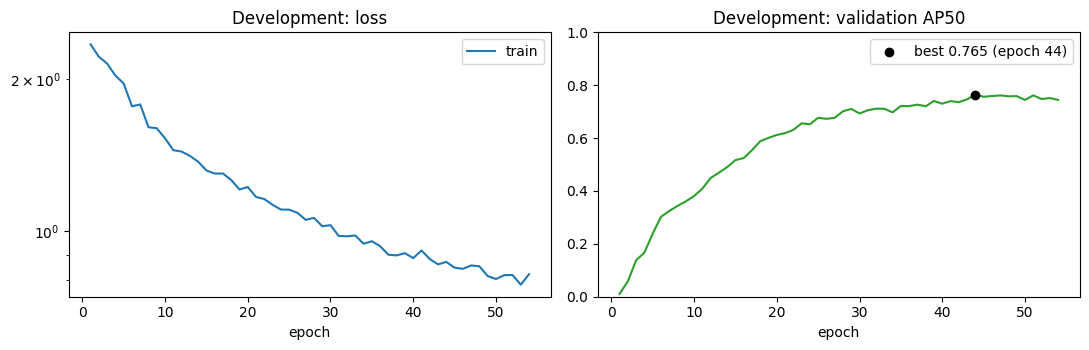

In [77]:
checkpoint = FasterRCNNRun(RUNS / SOURCE_RUN).trained_checkpoint() if SOURCE_RUN else RUN.trained_checkpoint()
assert not SOURCE_RUN or checkpoint is not None, f"No finished training in {RUNS / SOURCE_RUN}"
if checkpoint is None:
    checkpoint = frcnn_develop(CONFIG, DATASET, RUN, DEVICE)
else:
    CONFIG = FasterRCNNConfig.from_dict(torch.load(checkpoint, map_location="cpu", weights_only=True)["config"])
    print(f"Loaded finished training: {checkpoint}\nSettings: {CONFIG.to_dict()}")
with (Path(checkpoint).parent / "history.csv").open(encoding="utf-8") as handle:
    history = [{key: float(value) for key, value in row.items() if value != ""} for row in csv.DictReader(handle)]
plot_history(history, "Development")

## 8. Validation

Settings are chosen here and frozen for the test: the RPN NMS IoU with the best AP50 and the operating confidence
with the best F1. Original and public validation images are reported separately to expose any domain gap.

Loaded finished validation:
REAL DATA - declared split: valid

Faster R-CNN | valid | 92 images
AP50=0.7901  AP50:95=0.3764
Operating confidence=0.400  matching IoU=0.50
Precision=0.3526  Recall=0.8356  F1=0.4959  matched IoU=0.7359
TP=122  FP=224  FN=24
  drill: AP50=0.9584  AP50:95=0.4611  objects=52
  scissor: AP50=0.8448  AP50:95=0.4383  objects=47
  screwdriver: AP50=0.5671  AP50:95=0.2296  objects=47
  origin:original: 17 images, 42 objects, AP50=0.8475, AP50:95=0.4049
  origin:public: 75 images, 104 objects, AP50=0.7699, AP50:95=0.3759
NMS IoU=0.70
Parameters=17978723  checkpoint bytes=71964945

Pre-NMS anchor trials (AP50 / screwdriver AP50): {(6000, 0.5): (0.7304, 0.4308), (6000, 0.7): (0.7646, 0.5302), (12000, 0.5): (0.7472, 0.4738), (12000, 0.7): (0.7822, 0.5531), (24000, 0.5): (0.7709, 0.5161), (24000, 0.7): (0.7901, 0.5671), (48000, 0.5): (0.7809, 0.5274), (48000, 0.7): (0.7899, 0.5669)}
RPN NMS trials: {0.5: 0.7709, 0.7: 0.7901}
Confidence trials (F1): {0.2: 0.3748, 0.3: 

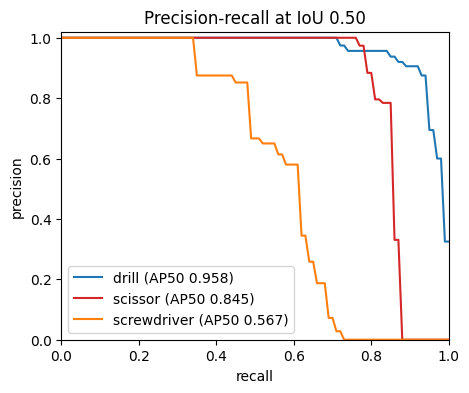

In [85]:
validation = RUN.result("validation")
if validation is None:
    validation = frcnn_validate(checkpoint, DATASET, RUN, DEVICE)
else:
    print("Loaded finished validation:\n" + (RUN.report("validation") / "metrics.txt").read_text())
protocol = load_json(RUN.protocol_path)
settings = protocol["models"][FRCNN_NAME]
if "pre_nms_trials" in settings:
    print("Pre-NMS anchor trials (AP50 / screwdriver AP50):", {(row["rpn_pre_nms"], row["nms_iou"]):
          (round(row["map50"], 4), round(row["class_ap50"]["screwdriver"], 4)) for row in settings["pre_nms_trials"]})
print("RPN NMS trials:", {row["nms_iou"]: round(row["map50"], 4) for row in protocol["nms_trials"][FRCNN_NAME]})
print("Confidence trials (F1):", {row["confidence"]: round(row["micro_f1"], 4) for row in settings["confidence_trials"]})
print(f"Frozen settings: {settings.get('rpn_pre_nms', 6000)} anchors before RPN NMS, RPN NMS IoU "
      f"{settings['nms']['nms_iou']}, final NMS IoU {settings['nms']['final_nms_iou']}, "
      f"operating confidence {settings['operating_confidence']}")
plot_pr_curves(validation)

**Where objects are lost** (Person 2's diagnostics). For each validation object: does any RPN proposal cover it at
IoU ≥ 0.5 (all proposals / top 100), and does the RoI head name the right class when given the exact ground-truth
box? A class with low coverage is lost in the RPN; one with good coverage but low AP is lost in the RoI head.

In [86]:
detector = FasterRCNNDetector.from_checkpoint(checkpoint, DEVICE, protocol)
diagnostics = pipeline_diagnostics(detector, ToolDataset(DATASET, "valid"))
print(f"{'class':<13}{'objects':>8}{'RPN covered':>13}{'top 100':>9}{'RoI correct on exact box':>26}")
for name, row in diagnostics.items():
    print(f"{name:<13}{row['objects']:>8}{row['rpn_covered']:>13}{row['rpn_top100_covered']:>9}"
          f"{row['roi_correct_on_exact_boxes']:>26}")

class         objects  RPN covered  top 100  RoI correct on exact box
drill              52           52       52                        50
scissor            47           42       39                        42
screwdriver        47           36       26                        38


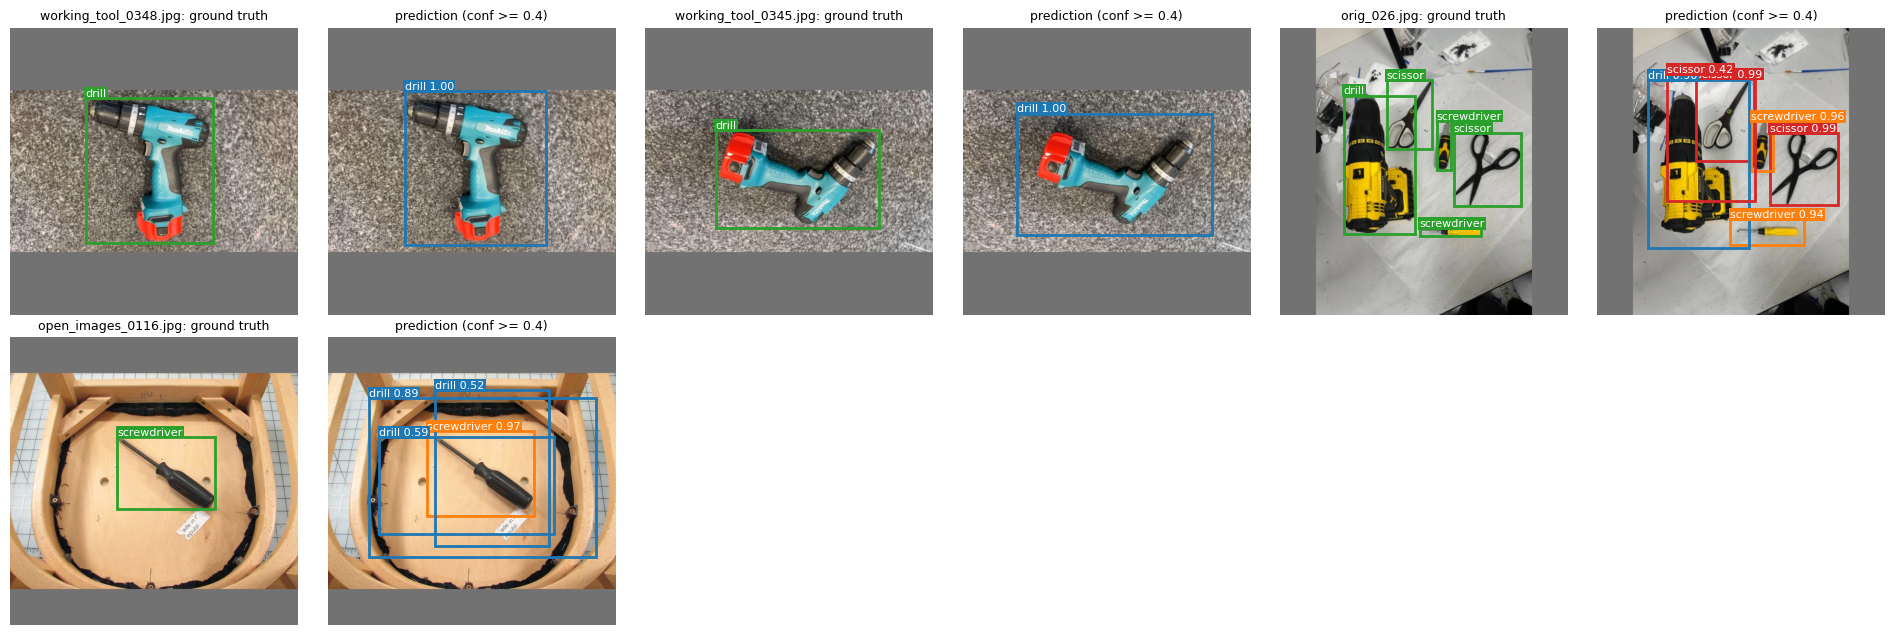

In [87]:
valid_truth = load_ground_truth(DATASET, "valid")
examples = pick_examples(validation)
shown = examples["success"][:2] + examples["missed_object"] + examples["background_or_low_overlap"]
if shown:
    show_predictions(detector, DATASET, "valid", valid_truth, shown)

## 9. Final test

Retrains from ImageNet on train + validation (450 images) for the development run's best epoch count, with every
setting frozen, then evaluates **once** on the 50 original test photos and measures inference speed (batch 1,
including preprocessing, decoding and NMS).

In [88]:
test = RUN.result("test")
if test is None and RUN_FINAL_TEST:
    test = frcnn_final_test(RUN, DATASET, DEVICE)
elif test is not None:
    print("Loaded the finished test (it is never repeated):\n" + (RUN.report("test") / "metrics.txt").read_text())
if test is not None:
    timing = test["model_metadata"]["benchmark"]
    size = test["model_metadata"]["model_size"]
    print(f"Speed: {timing['mean_latency_ms']:.1f} ms/image ({timing['sequential_fps']:.1f} FPS) on {timing['device']}")
    print(f"Model: {size['parameter_count']:,} parameters, checkpoint {size['checkpoint_file_bytes'] / 1e6:.1f} MB")
    plot_pr_curves(test)
else:
    print("Final test not run. Set RUN_FINAL_TEST = True once every setting is fixed on validation.")

Final test not run. Set RUN_FINAL_TEST = True once every setting is fixed on validation.


## 10. Error analysis

Error types at the operating confidence, on the test split if it has been run, otherwise on validation. Categories
describe each mistake; they are not proven causes.

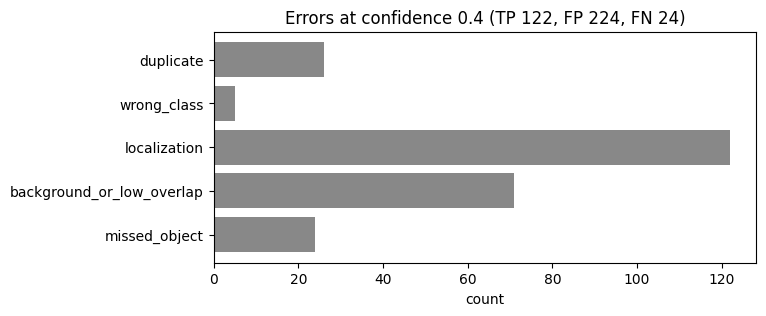

missed object


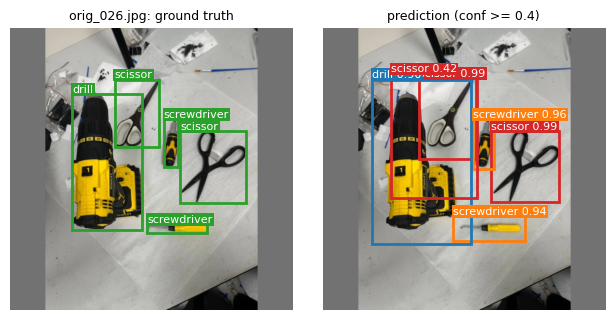

background or low overlap


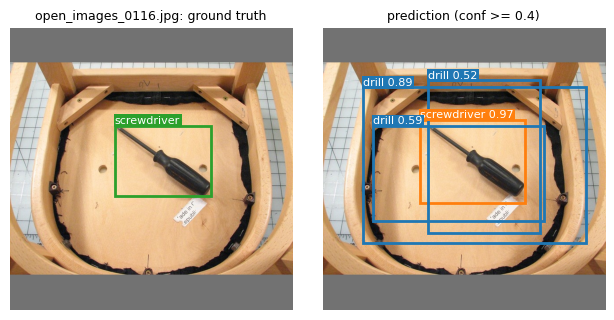

localization


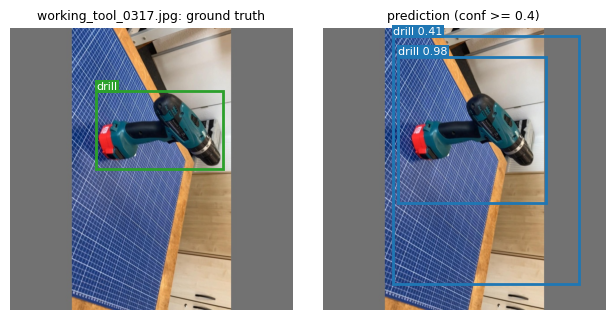

wrong class


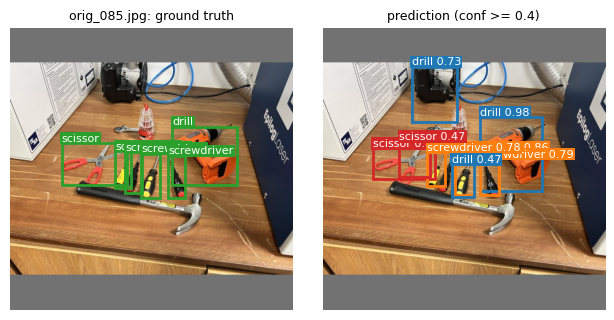

In [89]:
analysed, analysed_split = (test, "test") if test else (validation, "valid")
counts = plot_error_breakdown(analysed)
if test:
    detector = FasterRCNNDetector.from_checkpoint(RUN.final_checkpoint(), DEVICE, protocol)
truth = load_ground_truth(DATASET, analysed_split, allow_test=analysed_split == "test")
examples = pick_examples(analysed)
for kind, ids in examples.items():
    if ids and kind != "success":
        print(kind.replace("_", " "))
        show_predictions(detector, DATASET, analysed_split, truth, ids)

## 11. Inference on photos

`predict_image` takes a photo of any size, letterboxes it like the training data, detects and maps the boxes back to
the photo's pixels. This is the same call the browser demo uses.

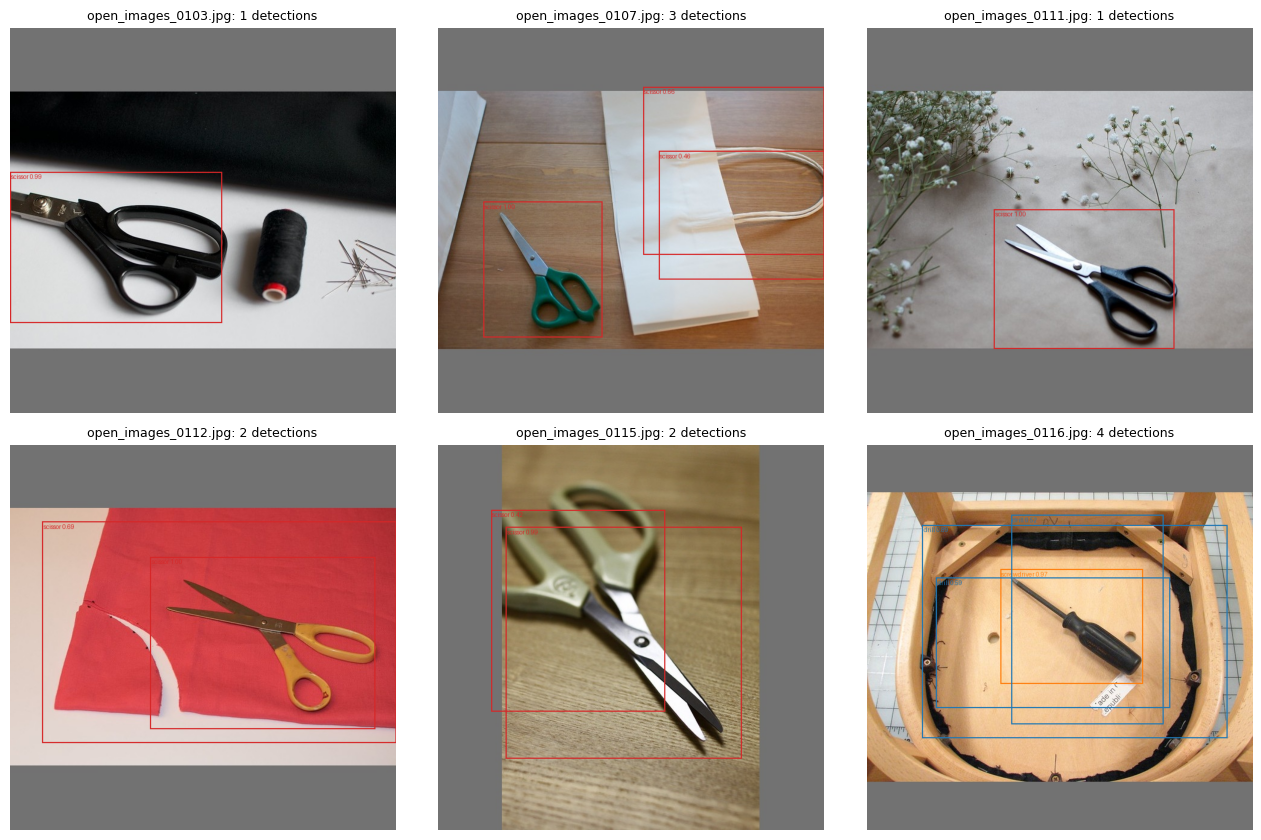

In [90]:
split = "test" if test else "valid"
folder = DATASET / split / "images"
photos = sorted(folder.iterdir())[:6]
_, axes = plt.subplots(2, 3, figsize=(13, 8.5))
for axis, path in zip(axes.flat, photos):
    image = Image.open(path).convert("RGB")
    found = detector.predict_image(image)
    axis.imshow(draw_detections(image, found))
    axis.set_title(f"{path.name}: {len(found)} detections", fontsize=9)
    axis.axis("off")
plt.tight_layout()
plt.show()
if test is not None:  # every test photo with its detections, for the demo video
    saved = RUN.root / "test_predictions"
    saved.mkdir(exist_ok=True)
    for path in sorted(folder.iterdir()):
        image = Image.open(path).convert("RGB")
        draw_detections(image, detector.predict_image(image)).save(saved / path.name, quality=92)
    print(f"Saved {len(list(saved.iterdir()))} annotated test photos to {saved}")
# Your own photo: detector.predict_image(Image.open("photo.jpg").convert("RGB"))

## 12. Results and conclusions

Achieved AP50 against the targets in the proposal (sections 1.3 and 1.4).

In [91]:
final = test or validation
targets = {"overall": 0.70, "drill": 0.75, "scissor": 0.65, "screwdriver": 0.70}
f3 = lambda value, width: f"{'n/a':>{width}}" if value is None else f"{value:>{width}.3f}"
print(f"{'split: ' + ('test (50 originals)' if test else 'validation (not the final result)'):<40}")
print(f"{'':<14}{'AP50':>8}{'target':>9}{'AP50:95':>10}{'precision':>11}{'recall':>8}{'F1':>7}")
print(f"{'overall':<14}{f3(final['map50'], 8)}{targets['overall']:>9.2f}{f3(final['map_iou_average'], 10)}"
      f"{f3(final['precision_micro'], 11)}{f3(final['recall_micro'], 8)}{f3(final['f1_micro'], 7)}")
for row in final["per_class"]:
    print(f"{row['class_name']:<14}{f3(row['ap50'], 8)}{targets[row['class_name']]:>9.2f}{f3(row['ap_iou_average'], 10)}"
          f"{f3(row['precision'], 11)}{f3(row['recall'], 8)}{f3(row['f1'], 7)}")
for name, subset in final["subsets"].items():
    print(f"{name:<22} AP50 {f3(subset['map50'], 0).strip()} ({subset['image_count']} images)")
print(f"\nRun folder: {RUN.root.resolve()}")

split: validation (not the final result)
                  AP50   target   AP50:95  precision  recall     F1
overall          0.790     0.70     0.376      0.353   0.836  0.496
drill            0.958     0.75     0.461      0.389   0.981  0.557
scissor          0.845     0.65     0.438      0.465   0.851  0.602
screwdriver      0.567     0.70     0.230      0.240   0.660  0.352
origin:original        AP50 0.847 (17 images)
origin:public          AP50 0.770 (75 images)

Run folder: /content/drive/MyDrive/EE3703_frcnn_runs/frcnn_stride8_v3_20261105_1338


### Conclusions

*To be written from the results above:* how close each class came to its target; whether objects are lost in the RPN
or the RoI head (section 8); what the error analysis shows; how Faster R-CNN compares with YOLOv2 on accuracy and
speed; and what would improve it next.